<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070-vqe-ansatz.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070. The variational quantum eigensolver and the choice of ansatz

The ground state of an interacting chain of $N$ spins is a vector of $2^N$ complex amplitudes. A quantum register holds such a state without writing it down, and the variational quantum eigensolver (VQE) uses this property to search for ground states [1, 2]. A circuit with adjustable gate angles $\boldsymbol\theta=(\theta_1,\dots,\theta_n)$ prepares a trial state $|\psi(\boldsymbol\theta)\rangle$ on the register, the device measures its energy, and a classical computer changes the angles so that the energy decreases. The family of states that one circuit layout can prepare is called the ansatz. The ansatz limits the quality of the trained state, so the circuit has to be chosen with the physics of the target state in mind.

We study this choice on two spin chains of $N=6$ qubits, the transverse-field Ising chain and the Heisenberg chain, whose ground states we also obtain by exact diagonalisation of the Hamiltonian. Of the three ansätze we compare, the hardware-efficient ansatz uses the gates that a device offers natively [3]. The Hamiltonian-variational ansatz is built from the terms of the Ising Hamiltonian [4, 5], and a symmetry-preserving ansatz for the Heisenberg chain keeps the total magnetisation fixed. Each trained state is judged by its energy, by its fidelity with the exact ground state and by its half-chain entanglement entropy. The entropy reveals errors that the energy hides, and in the ordered phase of the Ising chain it separates a circuit that finds the ground state from one that settles in a symmetry-broken state of almost the same energy.

All results come from exact state-vector simulations, which compute the energy and its gradient from the full vector of amplitudes, whereas a quantum device estimates them from measured bit strings. Sections 2 to 14 form the core route, which ends with a comparison table of the ansätze. Sections 15 to 17, on the circuit depth, the first excited state and the phase diagram of an eight-qubit Ising chain, can be finished at home. On a laptop CPU the core route runs in under a minute and all cells together in two to four minutes, depending on the load of the machine.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that the identities checked by `assert` hold to about $10^{-10}$. JAX computes the circuits and their gradients on the CPU, SciPy diagonalises the sparse Hamiltonians, pandas prints the comparison table and Matplotlib draws the figures. The cells run in order, and every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # small dense calculations; the CPU avoids GPU memory allocation
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
from scipy.linalg import expm
import pandas as pd
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
COL = {"HEA": "#005CA7", "HVA": "#D35A05", "SPA": "#1B7F36"}  # course palette, one colour per ansatz
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
def panel(ax, letter):
    ax.text(0.03, 0.96, f"({letter})", transform=ax.transAxes, ha="left", va="top", fontsize=11, zorder=10,
            bbox=dict(fc="white", ec="none", pad=1.0))
def sci(x, digits=1):
    # a number as LaTeX scientific notation, e.g. 2.1\times10^{-3}
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
started = time.perf_counter()
NUMBERS = {}
key = jax.random.PRNGKey(70)
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Two spin chains and their exact ground states

The transverse-field Ising model (TFIM) describes spins on a line that interact through their $z$ components and feel a magnetic field along $x$. For an open chain of $N$ qubits its Hamiltonian is
$$\hat{\mathcal H}_{\rm TFIM}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i , \tag{1}$$
where $\hat Z_i$ and $\hat X_i$ are Pauli operators on qubit $i$, $J=1$ is the coupling and $h$ is the transverse field. The coupling favours neighbours aligned along $z$, both in $|0\rangle$ or both in $|1\rangle$, while the field favours every spin in $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$. The two terms do not commute, and in an infinite chain their competition produces a quantum phase transition at $h=J$. We take the critical field $h=1$ and the field $h=0.5$ of the ordered phase, in which the spins tend to align along $z$.

Both terms of equation (1) commute with the parity
$$\hat\Pi=\prod_{i=0}^{N-1}\hat X_i , \tag{2}$$
which flips every spin, $|b_0b_1\dots b_{N-1}\rangle\to|\bar b_0\bar b_1\dots\bar b_{N-1}\rangle$ with $\bar b=1-b$. The eigenstates of $\hat{\mathcal H}_{\rm TFIM}$ therefore have a definite parity, $+1$ or $-1$. In the ordered phase the two lowest levels lie close to the even and the odd superposition of the two aligned configurations $|0\dots0\rangle$ and $|1\dots1\rangle$. Their energy splitting is much smaller than $J$.

The second model is the XXZ chain,
$$\hat{\mathcal H}_{\rm XXZ}=J\sum_{i=0}^{N-2}\big(\hat X_i\hat X_{i+1}+\hat Y_i\hat Y_{i+1}+\Delta\,\hat Z_i\hat Z_{i+1}\big) , \tag{3}$$
with $J=1$ and the anisotropy $\Delta$. We study $\Delta=1$, the antiferromagnetic Heisenberg chain. On a pair of qubits the operator $\hat X\hat X+\hat Y\hat Y=2(|01\rangle\langle10|+|10\rangle\langle01|)$ exchanges a $0$ and a $1$ between neighbours, and $\hat Z\hat Z$ is diagonal. Neither term changes the number of bits equal to $1$, so the Hamiltonian conserves the total magnetisation
$$\hat Z_{\rm tot}=\sum_{i=0}^{N-1}\hat Z_i . \tag{4}$$
For even $N$ the Heisenberg ground state lies in the sector $\hat Z_{\rm tot}=0$, which for $N=6$ is spanned by the bit strings with three zeros and three ones.

For six qubits the Hamiltonians are $64\times64$ matrices. We build them as sparse Kronecker products and find the lowest eigenvalues with the Lanczos routine `eigsh` of SciPy, which builds the lowest eigenvectors from repeated products of the matrix with a vector. Dense diagonalisation checks the result. From each spectrum we keep the ground-state energy $E_0$, the first excited energy $E_1$, the gap $\Delta E=E_1-E_0$ and the ground state $|\psi_0\rangle$. The half-chain entanglement entropy of a state $|\psi\rangle$ follows from its Schmidt decomposition across the cut between qubits 2 and 3. We reshape the 64 amplitudes into an $8\times8$ matrix whose rows are labelled by $b_0b_1b_2$ and whose columns are labelled by $b_3b_4b_5$. Its singular values $s_k$ are the Schmidt coefficients, and the entropy in bits is
$$S_{\rm vN}=-\sum_k s_k^2\log_2 s_k^2 . \tag{5}$$
A state that is a product across the cut has $S_{\rm vN}=0$, and one Bell pair shared between the two halves contributes one bit.

In [2]:
N = 6
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

def op_on(ops, N=N):
    # sparse Kronecker product with ops[q] on qubit q and the identity elsewhere; qubit 0 is the leftmost factor
    out = sp.identity(1, dtype=complex, format="csr")
    for q in range(N):
        out = sp.kron(out, sp.csr_matrix(ops.get(q, I2)), format="csr")
    return out

def tfim_hamiltonian(h, J=1.0, N=N):
    bonds = sum(op_on({i: Z, i + 1: Z}, N) for i in range(N - 1))
    field = sum(op_on({i: X}, N) for i in range(N))
    return (-J * bonds - h * field).tocsr()

def xxz_hamiltonian(Delta, J=1.0, N=N):
    return sum(J * (op_on({i: X, i + 1: X}, N) + op_on({i: Y, i + 1: Y}, N) + Delta * op_on({i: Z, i + 1: Z}, N))
               for i in range(N - 1)).tocsr()

def half_chain_entropy(psi, N=N):
    # equation (5): Schmidt coefficients of the 2^(N/2) x 2^(N/2) amplitude matrix, entropy in bits
    s = np.linalg.svd(np.asarray(psi).reshape(2 ** (N // 2), -1), compute_uv=False)
    lam = s[s > 1e-9] ** 2
    return float(-(lam * np.log2(lam)).sum())

MODELS = {"TFIM h=1": tfim_hamiltonian(1.0), "TFIM h=0.5": tfim_hamiltonian(0.5), "XXZ Delta=1": xxz_hamiltonian(1.0)}
PARITY = op_on({q: X for q in range(N)})
ZTOT = sum(op_on({q: Z}) for q in range(N))
EXACT, rows = {}, []
for name, Hs in MODELS.items():
    w, v = eigsh(Hs, k=4, which="SA")
    order = np.argsort(w); w, v = w[order], v[:, order]
    assert np.allclose(w, np.linalg.eigvalsh(Hs.toarray())[:4], atol=TOL)     # Lanczos agrees with dense diagonalisation
    psi0, psi1 = v[:, 0], v[:, 1]
    expect = lambda O, p: float(np.real(np.vdot(p, O @ p)))
    EXACT[name] = dict(E0=w[0], E1=w[1], gap=w[1] - w[0], psi0=psi0, psi1=psi1, S=half_chain_entropy(psi0),
                       H=jnp.asarray(Hs.toarray()))
    ising = name.startswith("TFIM")
    rows.append({"model": name, "E_0": w[0], "E_1": w[1], "gap E_1-E_0": w[1] - w[0], "E_2": w[2],
                 "S_vN (bits)": EXACT[name]["S"], "<P> ground": expect(PARITY, psi0) if ising else np.nan,
                 "<P> first excited": expect(PARITY, psi1) if ising else np.nan, "<Z_tot> ground": expect(ZTOT, psi0)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
for name in ("TFIM h=1", "TFIM h=0.5"):
    assert abs(rows[list(MODELS).index(name)]["<P> ground"] - 1) < TOL      # even ground state
    assert abs(rows[list(MODELS).index(name)]["<P> first excited"] + 1) < TOL  # odd first excited state
assert abs(np.vdot(EXACT["XXZ Delta=1"]["psi0"], (ZTOT @ ZTOT) @ EXACT["XXZ Delta=1"]["psi0"])) < TOL   # sector Z_tot = 0
for name, tag in (("TFIM h=1", "Crit"), ("TFIM h=0.5", "Ord"), ("XXZ Delta=1", "Heis")):
    NUMBERS[f"EZero{tag}"] = f"{EXACT[name]['E0']:.4f}"
    NUMBERS[f"Gap{tag}"] = f"{EXACT[name]['gap']:.4f}"
    NUMBERS[f"S{tag}"] = f"{EXACT[name]['S']:.3f}"

      model     E_0     E_1  gap E_1-E_0     E_2  S_vN (bits)  <P> ground  <P> first excited  <Z_tot> ground
   TFIM h=1 -7.2962 -6.8141       0.4821 -5.8778       0.4732      1.0000            -1.0000         -0.0000
 TFIM h=0.5 -5.5220 -5.4986       0.0235 -4.2203       0.9636      1.0000            -1.0000          0.0000
XXZ Delta=1 -9.9743 -8.0080       1.9663 -8.0080       1.0263         NaN                NaN         -0.0000


The critical Ising chain has a gap of about half the coupling and a ground-state entropy of about half a bit. In the ordered chain the gap shrinks to a few hundredths of $J$. The ground state carries almost one bit of entropy, the signature of a superposition of the two aligned configurations. At both fields the ground state is even and the first excited state is odd under $\hat\Pi$. The Heisenberg ground state lies in the sector $\hat Z_{\rm tot}=0$ and has the largest entropy of the three. Its first excited level is three-fold degenerate, $E_1=E_2=E_3$, because it is a spin triplet, so for this chain we use only $E_0$ and the gap.

## 3. The state-vector simulator

A state-vector simulator written in JAX computes the trial states. The state of $N$ qubits is stored as a rank-$N$ tensor $\psi[b_0,\dots,b_{N-1}]$ of shape $(2,\dots,2)$, the C-order reshape of the $2^N$ amplitudes with qubit 0 as the most significant bit. A one-qubit gate with the $2\times2$ matrix $U$ acts on qubit $q$ by contracting $U$ with leg $q$ of the tensor. A two-qubit gate on qubits $q$ and $r$ contracts its matrix, reshaped to a $2\times2\times2\times2$ tensor, with legs $q$ and $r$. Every gate is a rotation generated by a Pauli string $\hat P$,
$$\hat R_{\hat P}(\theta)=e^{-i\theta\hat P/2}=\cos\frac\theta2\,\hat I-i\sin\frac\theta2\,\hat P , \tag{6}$$
where the second form follows from $\hat P^2=\hat I$. On a device the angle is a pulse area, $\theta=\Omega t$ for a single-qubit drive with Rabi frequency $\Omega$ applied for a time $t$, and $\theta=Jt$ for a two-qubit interaction of strength $J$.

The controlled-$Z$ gate $\widehat{\rm CZ}$ multiplies the amplitude of $|11\rangle$ by $-1$ and leaves the other three unchanged. It is diagonal, so a chain of CZ gates on all neighbouring pairs multiplies the amplitude of $b_0\dots b_{N-1}$ by $(-1)^{\sum_q b_qb_{q+1}}$. The simulator therefore applies the whole chain as one elementwise product. The energy of a state is $E=\langle\psi|\hat{\mathcal H}|\psi\rangle$, evaluated with the dense $64\times64$ matrix of Section 2, and `entropy_bits` evaluates equation (5) inside JAX. The code checks the contractions against Kronecker products and the entropy against the exact references.

In [3]:
# recap: JAX state-vector simulator on the rank-N tensor psi[b_0, ..., b_{N-1}]
def apply_1q(psi, U, q):
    # contract the 2x2 matrix U with leg q
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)

def apply_2q(psi, U, q, r):
    # contract the 4x4 matrix U (basis 00, 01, 10, 11 of qubits q, r) with legs q and r
    out = jnp.tensordot(U.reshape(2, 2, 2, 2), psi, axes=([2, 3], [q, r]))
    return jnp.moveaxis(out, [0, 1], [q, r])

def rx(t):  # exp(-i t X / 2)
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    return jnp.array([[c, -1j * s], [-1j * s, c]], dtype=CDTYPE)
def ry(t):  # exp(-i t Y / 2)
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)
def rz(t):  # exp(-i t Z / 2)
    return jnp.diag(jnp.array([jnp.exp(-0.5j * t), jnp.exp(0.5j * t)], dtype=CDTYPE))

BITS = np.array(list(itertools.product([0, 1], repeat=N)))          # row i = bit string of basis index i
assert BITS[5].tolist() == [0, 0, 0, 1, 0, 1]                       # qubit 0 is the most significant bit
SPIN = 1 - 2 * BITS                                                 # eigenvalue of Z_q: +1 for bit 0, -1 for bit 1
CZ_CHAIN = jnp.asarray(np.prod([(-1.0) ** (BITS[:, q] * BITS[:, q + 1]) for q in range(N - 1)], axis=0).reshape((2,) * N))
ZERO = jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)    # |0...0>

def energy(psi, H):
    return jnp.real(jnp.vdot(psi, H @ psi))

def entropy_bits(psi):
    # equation (5) for a state vector of length 2^N, cut between qubits N/2-1 and N/2
    s = jnp.linalg.svd(psi.reshape(2 ** (N // 2), -1), compute_uv=False)
    p = s ** 2
    safe = jnp.where(p > 1e-14, p, 1.0)
    return -jnp.sum(jnp.where(p > 1e-14, p * jnp.log2(safe), 0.0))

# checks: tensor contractions against Kronecker products, the CZ chain, the entropy
k1, k2 = jax.random.split(jax.random.PRNGKey(7001))
psi_r = jax.random.normal(k1, (2 ** N,)) + 1j * jax.random.normal(k2, (2 ** N,)); psi_r = psi_r / jnp.linalg.norm(psi_r)
U1 = np.asarray(rz(0.4) @ ry(1.1))
assert np.allclose(apply_1q(psi_r.reshape((2,) * N), jnp.asarray(U1), 2).reshape(-1), op_on({2: U1}) @ np.asarray(psi_r), atol=TOL)
U2 = expm(-0.35j * np.kron(X, Y))
U2_kron = sp.kron(sp.kron(sp.identity(8), sp.csr_matrix(U2)), sp.identity(2)).toarray()   # acts on qubits 3 and 4
assert np.allclose(apply_2q(psi_r.reshape((2,) * N), jnp.asarray(U2), 3, 4).reshape(-1), U2_kron @ np.asarray(psi_r), atol=TOL)
CZ = np.diag([1, 1, 1, -1]).astype(complex)
cz_chain_kron = np.eye(2 ** N, dtype=complex)
for q in range(N - 1):
    cz_chain_kron = sp.kron(sp.kron(sp.identity(2 ** q), sp.csr_matrix(CZ)), sp.identity(2 ** (N - q - 2))).toarray() @ cz_chain_kron
assert np.allclose(np.diag(cz_chain_kron), np.asarray(CZ_CHAIN).reshape(-1), atol=TOL)
for name in MODELS:
    assert abs(float(entropy_bits(jnp.asarray(EXACT[name]["psi0"]))) - EXACT[name]["S"]) < 1e-8
    assert abs(float(energy(jnp.asarray(EXACT[name]["psi0"]), EXACT[name]["H"])) - EXACT[name]["E0"]) < TOL
print("contractions, CZ chain, energy and entropy agree with the Kronecker-product references")

contractions, CZ chain, energy and entropy agree with the Kronecker-product references


## 4. Accuracy of a variational state

To judge a trained state we compare it with the exact ground state in three ways. We expand a normalised trial state in the eigenstates $|n\rangle$ of $\hat{\mathcal H}$, with energies $E_0<E_1\le E_2\le\dots$, as $|\psi\rangle=\sum_nc_n|n\rangle$. Its energy error is
$$E-E_0=\sum_{n\ge1}|c_n|^2(E_n-E_0)\ \ge\ \Delta E\sum_{n\ge1}|c_n|^2=\Delta E\,(1-F) , \tag{7}$$
where $F=|\langle\psi_0|\psi\rangle|^2=|c_0|^2$ is the fidelity with the exact ground state. Every term of the sum is non-negative, so $E\ge E_0$ for every trial state, which is the variational principle sketched below. Equation (7) also bounds the infidelity by the energy error, $1-F\le(E-E_0)/\Delta E$. A small energy error therefore guarantees a good state only when it is small compared with the gap, as the second sketch shows.

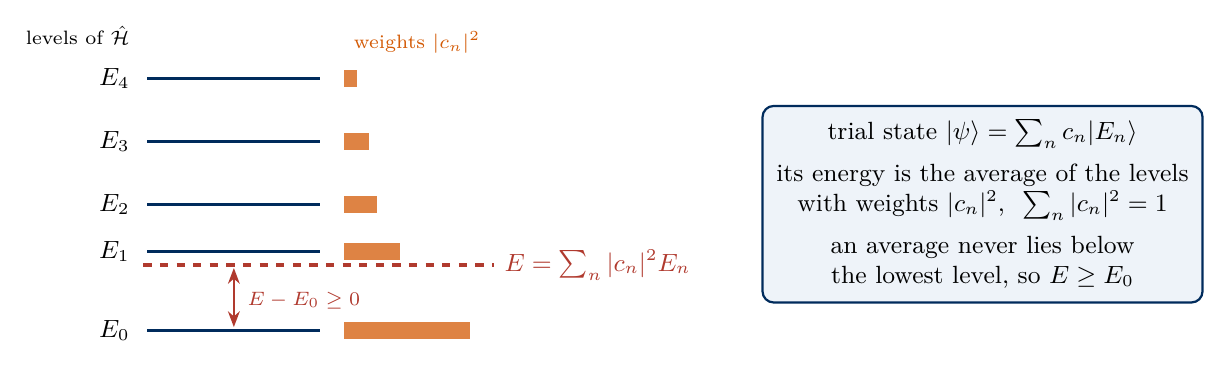

The trial energy is the average of the levels $E_n$ weighted by $|c_n|^2$, and an average never lies below the lowest level.

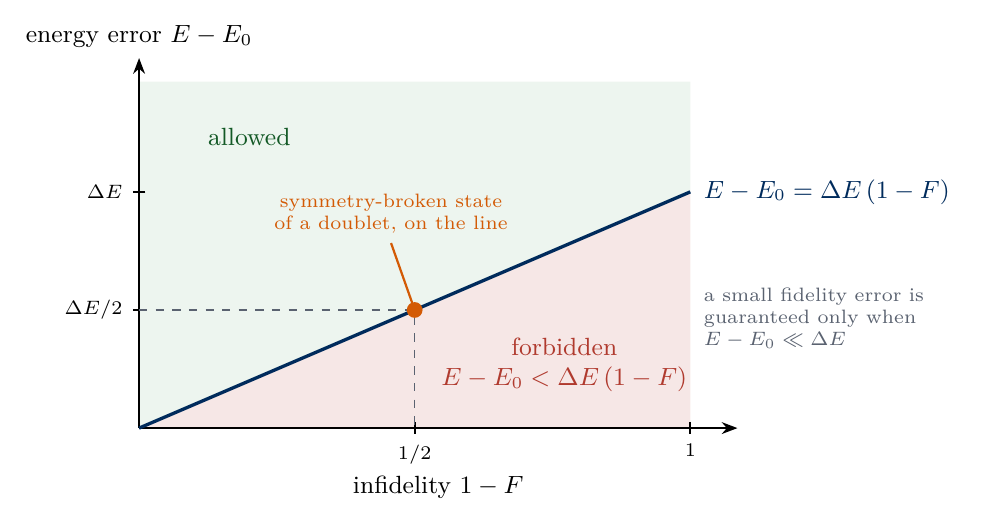

Every trial state lies on or above the line $E-E_0=\Delta E\,(1-F)$ of equation (7), and the symmetry-broken state of a doublet sits on this line at $1-F=1/2$.

The energy and the entanglement entropy respond differently to a small error in the state. We write the trial state as the ground state with a small admixture of amplitude $\epsilon$ of a normalised state $|\phi\rangle$ orthogonal to it,
$$|\psi\rangle=\frac{|\psi_0\rangle+\epsilon|\phi\rangle}{\sqrt{1+\epsilon^2}},\qquad 1-F=\frac{\epsilon^2}{1+\epsilon^2},\qquad E-E_0=\frac{\epsilon^2\big(\langle\phi|\hat{\mathcal H}|\phi\rangle-E_0\big)}{1+\epsilon^2} . \tag{8}$$
The cross terms of the energy vanish because $\hat{\mathcal H}|\psi_0\rangle=E_0|\psi_0\rangle$ and $\langle\phi|\psi_0\rangle=0$, so the energy error is of second order in $\epsilon$, like the infidelity. The entropy has no such stationary point at $|\psi_0\rangle$, and its change is generically of first order,
$$S_{\rm vN}(\psi)-S_{\rm vN}(\psi_0)=\epsilon\,S_1+O(\epsilon^2) , \tag{9}$$
with a coefficient $S_1$ that depends on $|\phi\rangle$. The entropy error thus scales as $\sqrt{1-F}$ and exceeds the energy error of a nearly converged state. A trial state with a relative energy error of $10^{-4}$ can carry a visibly wrong entanglement, so we follow both quantities during training. We write $\delta E=(E-E_0)/|E_0|$ for the relative energy error and $\delta S=|S_{\rm vN}(\psi)-S_{\rm vN}(\psi_0)|$ for the entropy error.

## 5. The hardware-efficient ansatz

An ansatz has to meet four demands. It must contain a good approximation of the target state (expressibility), its angles must be trainable by gradient descent, it must use the native gates and the qubit connectivity of the hardware, and it should respect the symmetries of the Hamiltonian. In quantum chemistry the standard choice is the unitary coupled-cluster ansatz, which builds the trial state from excitations of electrons out of a reference configuration [1, 2, 12]. For spin chains we compare three ansätze that weigh these demands differently.

The hardware-efficient ansatz (HEA) is built from the gates that a device applies with the smallest errors, without reference to the Hamiltonian [3]. It starts from $|0\dots0\rangle$. Each of its $L$ layers rotates every qubit by $\hat R_y$ followed by $\hat R_z$, with independent angles, and then applies CZ gates on all neighbouring pairs. A final block of rotations closes the circuit,
$$|\psi_{\rm HEA}(\boldsymbol\theta)\rangle=\hat R^{(L)}\,\hat C_{\rm Z}\hat R^{(L-1)}\cdots\hat C_{\rm Z}\hat R^{(0)}|0\dots0\rangle,\qquad \hat R^{(\ell)}=\bigotimes_{q=0}^{N-1}\hat R_z(\theta^{z}_{\ell q})\,\hat R_y(\theta^{y}_{\ell q}) , \tag{10}$$
where $\hat C_{\rm Z}=\prod_{q=0}^{N-2}\widehat{\rm CZ}_{q,q+1}$ is the CZ chain. The circuit has $n=2N(L+1)$ angles and $(N-1)L$ CZ gates. One block $\hat R_z\hat R_y$ takes $|0\rangle$ to any single-qubit state, and the CZ layers create the entanglement. With growing depth the HEA approaches any state of the register. Its layers contain no information about the Hamiltonian, and its states mix the parity sectors of the Ising chain and the magnetisation sectors of the Heisenberg chain.

In [4]:
def hea_rotations(psi, t):
    # R_z R_y on every qubit; t has shape (N, 2) = (qubit, [y, z])
    for q in range(N):
        psi = apply_1q(psi, rz(t[q, 1]) @ ry(t[q, 0]), q)
    return psi

def hea_state(theta, L):
    # equation (10); theta has 2N(L+1) entries, reshaped to (layer, qubit, [y, z])
    th = theta.reshape(L + 1, N, 2)
    def layer(psi, t):
        return hea_rotations(psi, t) * CZ_CHAIN, None
    psi, _ = jax.lax.scan(layer, ZERO, th[:-1])
    return hea_rotations(psi, th[-1]).reshape(-1)

def hea_size(L):
    return dict(n=2 * N * (L + 1), two_qubit=(N - 1) * L)

psi_test = hea_state(jax.random.normal(jax.random.PRNGKey(7002), (hea_size(3)["n"],)), 3)
assert abs(jnp.linalg.norm(psi_test) - 1) < TOL
print("HEA, L = 6:", hea_size(6))

HEA, L = 6: {'n': 84, 'two_qubit': 30}


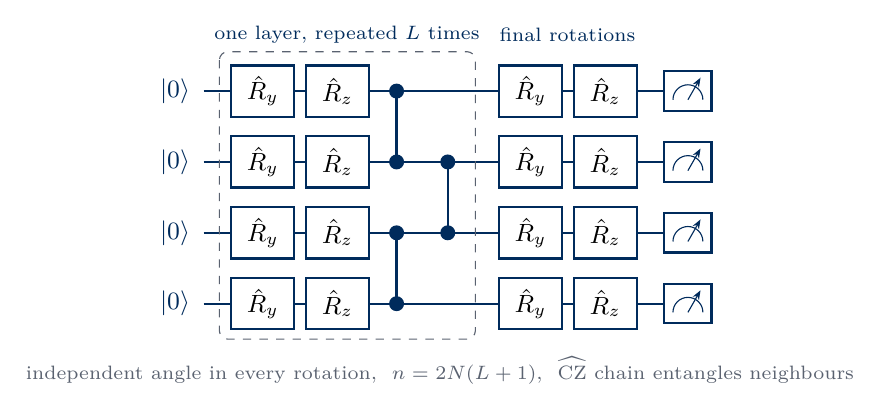

The sketch shows the HEA (10) for four qubits. The dashed box holds one layer, applied $L$ times, and the two columns after it are the closing rotations. Two dots joined by a vertical line denote a $\widehat{\rm CZ}$ gate. On six qubits the $\widehat{\rm CZ}$ gates on the pairs (0,1), (2,3), (4,5) act on different qubits and run in parallel. They are followed by those on (1,2) and (3,4), so one layer has depth two in two-qubit gates.

## 6. The Hamiltonian-variational ansatz

The Hamiltonian-variational ansatz (HVA) builds every layer from the evolution operators of the terms of the Hamiltonian [4, 5]. For the Ising chain it starts in $|+\rangle^{\otimes N}$, the ground state of the field term alone, and applies $L$ layers,
$$|\psi_{\rm HVA}(\boldsymbol\gamma,\boldsymbol\beta)\rangle=\hat V_L\cdots\hat V_2\hat V_1|+\rangle^{\otimes N},\qquad \hat V_\ell=e^{-i\beta_\ell\sum_i\hat X_i}\,e^{-i\gamma_\ell\sum_i\hat Z_i\hat Z_{i+1}} . \tag{11}$$
All bonds of a layer share the angle $\gamma_\ell$ and all qubits share $\beta_\ell$, so the circuit has only $n=2L$ parameters. In gates, $e^{-i\gamma_\ell\hat Z_i\hat Z_{i+1}}=\hat R_{zz}(2\gamma_\ell)$ on every bond and $e^{-i\beta_\ell\hat X_i}=\hat R_x(2\beta_\ell)$ on every qubit. A layer therefore contains $N-1$ two-qubit gates, as many as a layer of the HEA. Both exponents commute with the parity (2), and $|+\rangle^{\otimes N}$ has $\hat\Pi=+1$. Every state of the ansatz is therefore even, like the ground state of the Ising chain. The $\hat Z\hat Z$ terms commute with each other, and the simulator applies their product as one diagonal phase.

A Trotter decomposition approximates the evolution under a sum of non-commuting terms, $e^{-i(\hat A+\hat B)t}$, by a product of short evolutions $(e^{-i\hat At/m}e^{-i\hat Bt/m})^m$, which becomes exact as $m\to\infty$ [10]. Each layer $\hat V_\ell$ has the form of one such time step for $\hat{\mathcal H}_{\rm TFIM}$. We start the training from angles that discretise a slow sweep from the field term alone to the full Hamiltonian,
$$\gamma_\ell=-J\tau\,s_\ell,\qquad \beta_\ell=-h\tau\,(1-s_\ell),\qquad s_\ell=\frac{\ell-1/2}{L} , \tag{12}$$
with the time step $\tau=0.8/J$, and add random offsets of size $0.02$. The adiabatic theorem states that a system prepared in the ground state of a Hamiltonian stays in the instantaneous ground state when the Hamiltonian changes slowly compared with the inverse square of the gap [11]. A slow enough sweep from $|+\rangle^{\otimes N}$ therefore ends near the ground state, so equation (12) places the angles in a region of parameter space connected to it. The code checks the diagonal phase against the product of $\hat R_{zz}$ gates and the parity of random HVA states.

In [5]:
PLUS = jnp.ones((2,) * N, dtype=CDTYPE) / 2 ** (N / 2)                 # |+>^N
ZZ_SUM = jnp.asarray(sum(SPIN[:, q] * SPIN[:, q + 1] for q in range(N - 1)).reshape((2,) * N).astype(float))

def hva_state(theta, L):
    # equation (11); theta = (gamma_1, beta_1, ..., gamma_L, beta_L)
    th = theta.reshape(L, 2)
    def layer(psi, t):
        psi = psi * jnp.exp(-1j * t[0] * ZZ_SUM)       # exp(-i gamma sum_i Z_i Z_{i+1}), diagonal
        U = rx(2 * t[1])                                # exp(-i beta X) = R_x(2 beta)
        for q in range(N):
            psi = apply_1q(psi, U, q)
        return psi, None
    psi, _ = jax.lax.scan(layer, PLUS, th)
    return psi.reshape(-1)

def hva_size(L):
    return dict(n=2 * L, two_qubit=(N - 1) * L)

def hva_ramp(L, h, J=1.0, tau=0.8):
    # equation (12): a discretised sweep from -h sum X to the full Ising Hamiltonian
    s = (np.arange(1, L + 1) - 0.5) / L
    return np.stack([-J * tau * s, -h * tau * (1 - s)], axis=1).reshape(-1)

# check: the diagonal phase equals the product of R_zz(2 gamma) gates on all bonds
gamma = 0.37
RZZ = jnp.asarray(expm(-0.5j * (2 * gamma) * np.kron(Z, Z)))
psi_chk = PLUS
for q in range(N - 1):
    psi_chk = apply_2q(psi_chk, RZZ, q, q + 1)
assert jnp.allclose(psi_chk, PLUS * jnp.exp(-1j * gamma * ZZ_SUM), atol=TOL)

# parity of random states: HVA always +1, HEA anything
P_dense = jnp.asarray(PARITY.toarray())
th_hva = jax.random.uniform(jax.random.PRNGKey(7003), (200, 2 * 3), minval=-np.pi, maxval=np.pi)
th_hea = jax.random.uniform(jax.random.PRNGKey(7004), (200, hea_size(3)["n"]), minval=-np.pi, maxval=np.pi)
par_hva = jax.jit(jax.vmap(lambda t: energy(hva_state(t, 3), P_dense)))(th_hva)
par_hea = jax.jit(jax.vmap(lambda t: energy(hea_state(t, 3), P_dense)))(th_hea)
assert jnp.allclose(par_hva, 1.0, atol=TOL)
print(f"<P> over 200 random states, L = 3:  HVA in [{par_hva.min():+.3f}, {par_hva.max():+.3f}],  HEA in [{par_hea.min():+.3f}, {par_hea.max():+.3f}]")
print("HVA, L = 6:", hva_size(6), "| start angles (gamma, beta) per layer:", np.round(hva_ramp(6, 1.0).reshape(6, 2), 3).tolist())


<P> over 200 random states, L = 3:  HVA in [+1.000, +1.000],  HEA in [-0.356, +0.292]
HVA, L = 6: {'n': 12, 'two_qubit': 30} | start angles (gamma, beta) per layer: [[-0.067, -0.733], [-0.2, -0.6], [-0.333, -0.467], [-0.467, -0.333], [-0.6, -0.2], [-0.733, -0.067]]


Every random HVA state has parity $+1$ to numerical precision, whereas the parities of random HEA states scatter around zero. 

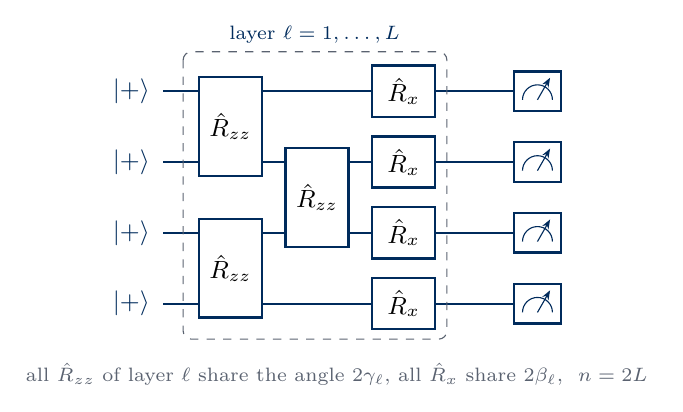

The sketch shows one HVA layer (11) for four qubits, with the $\hat R_{zz}(2\gamma_\ell)$ gates on the even and odd bonds followed by the $\hat R_x(2\beta_\ell)$ rotations, where all gates of one kind in a layer share their angle.

## 7. A symmetry-preserving ansatz for the Heisenberg chain

For the Heisenberg chain we build an ansatz that never leaves the sector $\hat Z_{\rm tot}=0$ of its ground state. It starts from the product of singlets $|\Psi^-\rangle=(|01\rangle-|10\rangle)/\sqrt2$ on the pairs (0,1), (2,3) and (4,5). This state has $\hat Z_{\rm tot}=0$ and is the ground state of equation (3) with the bonds (1,2) and (3,4) removed. Each layer applies the two-qubit gate
$$\hat G(\theta_{xy},\theta_{zz})=e^{-i\theta_{xy}(\hat X\hat X+\hat Y\hat Y)/2}\,e^{-i\theta_{zz}\hat Z\hat Z/2} , \tag{13}$$
first on the even bonds (0,1), (2,3), (4,5) and then on the odd bonds (1,2), (3,4), every gate with its own two angles. The two exponents commute, and in the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ the gate is
$$G=\begin{pmatrix}e^{-i\theta_{zz}/2}&0&0&0\\0&e^{i\theta_{zz}/2}\cos\theta_{xy}&-ie^{i\theta_{zz}/2}\sin\theta_{xy}&0\\0&-ie^{i\theta_{zz}/2}\sin\theta_{xy}&e^{i\theta_{zz}/2}\cos\theta_{xy}&0\\0&0&0&e^{-i\theta_{zz}/2}\end{pmatrix} . \tag{14}$$
It rotates the pair $|01\rangle,|10\rangle$ into each other and only adds phases to $|00\rangle$ and $|11\rangle$. No gate changes the number of ones, so every state of this symmetry-preserving ansatz (SPA) has $\hat Z_{\rm tot}=0$. The circuit has $n=2(N-1)L$ angles and $(N-1)L$ two-qubit gates. The gate $\hat G$ is the evolution operator of two qubits coupled by an anisotropic exchange interaction. We count it as one two-qubit gate, although a device whose native two-qubit gate is CZ would compile it into several.

In [6]:
BONDS = [(0, 1), (2, 3), (4, 5), (1, 2), (3, 4)]          # even bonds, then odd bonds

def xxz_gate(txy, tzz):
    # equation (14)
    c, s = jnp.cos(txy), jnp.sin(txy)
    a, b = jnp.exp(-0.5j * tzz), jnp.exp(0.5j * tzz)
    return jnp.array([[a, 0, 0, 0], [0, c * b, -1j * s * b, 0], [0, -1j * s * b, c * b, 0], [0, 0, 0, a]], dtype=CDTYPE)

assert np.allclose(xxz_gate(0.3, 0.7), expm(-0.15j * (np.kron(X, X) + np.kron(Y, Y))) @ expm(-0.35j * np.kron(Z, Z)), atol=TOL)
singlet = np.array([0, 1, -1, 0]) / np.sqrt(2)
SINGLETS = jnp.asarray(np.kron(np.kron(singlet, singlet), singlet).reshape((2,) * N).astype(complex))

def spa_state(theta, L):
    # equation (13) on even then odd bonds; theta reshaped to (layer, bond, [xy, zz])
    th = theta.reshape(L, len(BONDS), 2)
    def layer(psi, t):
        for k, (q, r) in enumerate(BONDS):
            psi = apply_2q(psi, xxz_gate(t[k, 0], t[k, 1]), q, r)
        return psi, None
    psi, _ = jax.lax.scan(layer, SINGLETS, th)
    return psi.reshape(-1)

def spa_size(L):
    return dict(n=2 * len(BONDS) * L, two_qubit=len(BONDS) * L)

# weight outside the sector Z_tot = 0 for random angles
outside = jnp.asarray(SPIN.sum(axis=1) != 0)
th_spa = jax.random.uniform(jax.random.PRNGKey(7005), (200, spa_size(3)["n"]), minval=-np.pi, maxval=np.pi)
w_spa = jax.jit(jax.vmap(lambda t: jnp.sum(jnp.abs(spa_state(t, 3)) ** 2 * outside)))(th_spa)
w_hea = jax.jit(jax.vmap(lambda t: jnp.sum(jnp.abs(hea_state(t, 3)) ** 2 * outside)))(th_hea)
assert w_spa.max() < TOL
print(f"weight outside Z_tot = 0 over 200 random states, L = 3:  SPA max {w_spa.max():.1e},  HEA mean {w_hea.mean():.3f}")
print("SPA, L = 6:", spa_size(6))


weight outside Z_tot = 0 over 200 random states, L = 3:  SPA max 0.0e+00,  HEA mean 0.696
SPA, L = 6: {'n': 60, 'two_qubit': 30}


The SPA keeps the whole weight in the sector $\hat Z_{\rm tot}=0$, while a random HEA state puts most of its weight outside it. 

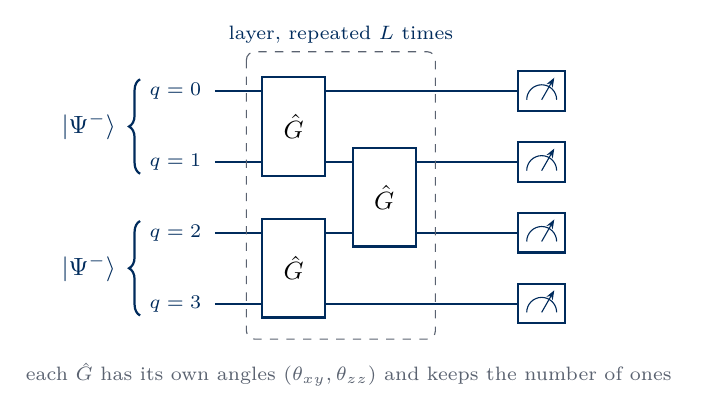

The sketch shows one SPA layer for four qubits, starting from two singlets $|\Psi^-\rangle$, where every gate $\hat G$ of equation (13) carries its own pair of angles $(\theta_{xy},\theta_{zz})$ and keeps the number of ones.

## 8. Entanglement capacity of a circuit

Only the gates that act across the cut between qubits 2 and 3 can change the half-chain entropy. Such a gate can be written as a sum of $r$ products, $\hat U=\sum_{k=1}^{r}\hat A_k\otimes\hat B_k$, with $\hat A_k$ acting on qubits 0 to 2 and $\hat B_k$ on qubits 3 to 5. Applied to a state with $\chi$ Schmidt terms it produces at most $r\chi$ terms, while gates inside one half leave the Schmidt coefficients unchanged. For the CZ gate $r=2$, since $\widehat{\rm CZ}=|0\rangle\langle0|\otimes\hat I+|1\rangle\langle1|\otimes\hat Z$, and the same holds for $\hat R_{zz}(\theta)=\cos\frac\theta2\,\hat I\otimes\hat I-i\sin\frac\theta2\,\hat Z\otimes\hat Z$. One layer of the HEA or of the HVA contains one such gate on the bond (2,3). After $L$ layers the number of Schmidt terms is at most $2^L$, and since the entropy (5) of $\chi$ terms is at most $\log_2\chi$,
$$S_{\rm vN}\le\min(L,\,N/2)\ \text{bits} , \tag{15}$$
where $N/2$ bits is the maximum for three qubits on each side. For the SPA the singlet on the pair (2,3) gives one bit at the start, and each gate (13) on the bond (2,3) has $r\le4$ and adds at most two bits. For the six-qubit chains studied here the exact entropies stay near one bit, so equation (15) allows them already at $L=1$. The sketch below shows the counting for a brickwork circuit.

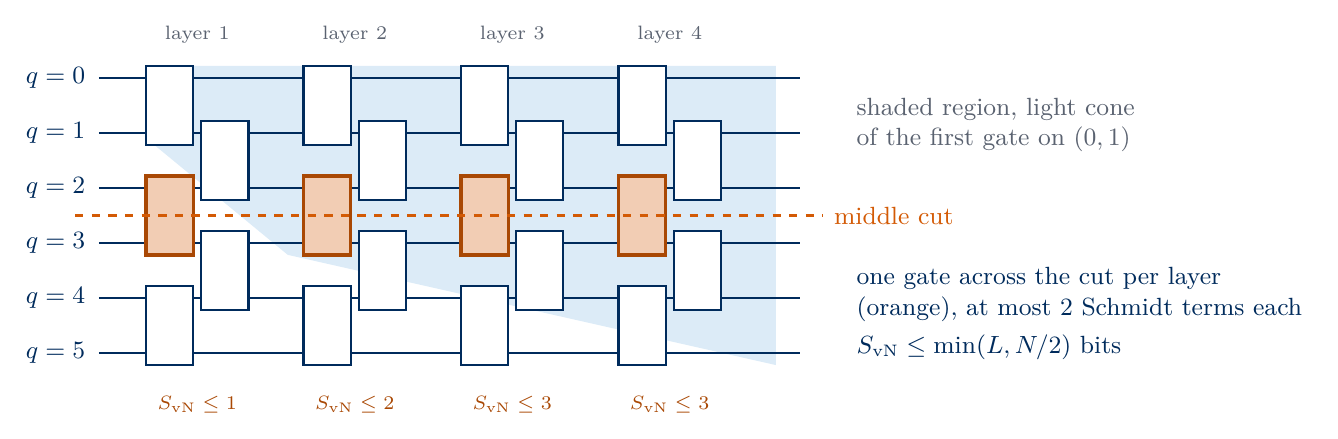

In a brickwork of six qubits one gate per layer crosses the middle cut (orange) and adds at most one bit to the half-chain entropy, while the light cone of the first gate (shaded) widens by one qubit on each side per layer.

To compare several depths inside one compiled function, we also write the HEA and the HVA for a maximum of $L_{\max}=6$ layers, of which only the first $L$ are applied. The inactive layers leave the state unchanged and their angles receive zero gradient. The circuit with $L$ active layers therefore coincides with the circuit (10) or (11) with $L$ layers, as the code checks. With these circuits we sample 400 random angle vectors at each depth $L=1$, $2$, $3$ and check the bound (15).

In [7]:
L_MAX = 6

def hea_state_depth(theta, depth):
    # equation (10) with L_MAX layers of which the first `depth` are applied, then the closing rotations
    th = theta.reshape(L_MAX + 1, N, 2)
    def layer(psi, x):
        t, ell = x
        return jnp.where(ell < depth, hea_rotations(psi, t) * CZ_CHAIN, psi), None
    psi, _ = jax.lax.scan(layer, ZERO, (th[:-1], jnp.arange(L_MAX)))
    return hea_rotations(psi, th[-1]).reshape(-1)

def hva_state_depth(theta, depth):
    # equation (11) with L_MAX layers of which the first `depth` are applied
    th = theta.reshape(L_MAX, 2)
    def layer(psi, x):
        t, ell = x
        new = psi * jnp.exp(-1j * t[0] * ZZ_SUM)
        U = rx(2 * t[1])
        for q in range(N):
            new = apply_1q(new, U, q)
        return jnp.where(ell < depth, new, psi), None
    psi, _ = jax.lax.scan(layer, PLUS, (th, jnp.arange(L_MAX)))
    return psi.reshape(-1)

# check: 3 active layers reproduce the circuits with L = 3
th_full = jax.random.normal(jax.random.PRNGKey(7006), ((L_MAX + 1) * N * 2,)).reshape(L_MAX + 1, N, 2)
assert jnp.allclose(hea_state_depth(th_full.reshape(-1), 3), hea_state(jnp.concatenate([th_full[:3], th_full[-1:]]).reshape(-1), 3), atol=TOL)
th_full = jax.random.normal(jax.random.PRNGKey(7007), (2 * L_MAX,))
assert jnp.allclose(hva_state_depth(th_full, 3), hva_state(th_full[:6], 3), atol=TOL)

# entanglement capacity: 400 random angle vectors at each depth
cap_depths = jnp.repeat(jnp.array([1, 2, 3]), 400)
kk = jax.random.split(jax.random.PRNGKey(7010), 2)
S_hea = jax.jit(jax.vmap(lambda t, d: entropy_bits(hea_state_depth(t, d))))(
    jax.random.uniform(kk[0], (cap_depths.size, 2 * N * (L_MAX + 1)), minval=-np.pi, maxval=np.pi), cap_depths)
S_hva = jax.jit(jax.vmap(lambda t, d: entropy_bits(hva_state_depth(t, d))))(
    jax.random.uniform(kk[1], (cap_depths.size, 2 * L_MAX), minval=-np.pi, maxval=np.pi), cap_depths)
cap_rows = []
for L in (1, 2, 3):
    sel = np.asarray(cap_depths == L)
    assert S_hea[sel].max() <= min(L, N // 2) + 1e-9 and S_hva[sel].max() <= min(L, N // 2) + 1e-9
    cap_rows.append({"L": L, "bound min(L, N/2)": min(L, N // 2), "max S_vN HEA": float(S_hea[sel].max()),
                     "max S_vN HVA": float(S_hva[sel].max())})
print(pd.DataFrame(cap_rows).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

 L  bound min(L, N/2)  max S_vN HEA  max S_vN HVA
 1                  1         0.998         1.000
 2                  2         1.661         1.956
 3                  3         1.652         2.613


The largest entropy among the random states stays below the bound at every depth, and at $L=1$ both ansätze come within a few hundredths of a bit of it.

## 9. Training with exact gradients

VQE minimises the energy $E(\boldsymbol\theta)=\langle\psi(\boldsymbol\theta)|\hat{\mathcal H}|\psi(\boldsymbol\theta)\rangle$ over the angles. In this simulation we compute $E(\boldsymbol\theta)$ from the state vector and its gradient by reverse-mode automatic differentiation with `jax.grad`. It returns all $n$ partial derivatives exactly at the cost of a few evaluations of the circuit. A quantum device has no access to the amplitudes and estimates every Pauli term of $\hat{\mathcal H}$ from bit strings measured in $G$ settings. For the Ising chain $G=2$ (all qubits measured along $z$, or all along $x$), and for the Heisenberg chain $G=3$. Each partial derivative follows from the parameter-shift rule [6, 7],
$$\frac{\partial E}{\partial\theta_k}=\frac{E(\boldsymbol\theta+\tfrac\pi2\mathbf e_k)-E(\boldsymbol\theta-\tfrac\pi2\mathbf e_k)}{2} , \tag{16}$$
which holds when $\theta_k$ enters a single gate $e^{-i\theta_k\hat P/2}$ with a Pauli string $\hat P$, and $\mathbf e_k$ is the unit vector along $\theta_k$. When a circuit angle $\varphi$ enters several gates $g$ with rotation angles $\theta_g=c_g\varphi$, as in the HVA, where $\gamma_\ell$ enters every $\hat R_{zz}(2\gamma_\ell)$ with $c_g=2$, the chain rule gives
$$\frac{\partial E}{\partial\varphi}=\sum_gc_g\frac{\partial E}{\partial\theta_g} , \tag{16a}$$
with every term from equation (16). The hardware cost therefore counts parametrised Pauli rotations $n_{\rm rot}$, the occurrences of angles in gates, which can exceed the number of free angles $n$. One hardware gradient costs $2n_{\rm rot}$ shifted circuits, each measured in $G$ settings with $M$ shots, and every estimated energy $\tilde E$ carries a statistical error of order $1/\sqrt M$. Our exact results correspond to the limit $M\to\infty$.

We update the angles with the Adam optimiser [8], implemented in a few lines of code. Adam rescales every gradient component by running averages of the gradient and of its square. The learning rate is $0.05$ for the HEA and the SPA and $0.02$ for the HVA, and every run takes 600 iterations. The HEA and the SPA start from angles drawn from a normal distribution of width $0.1$, close to their reference states $|0\dots0\rangle$ and the singlet product. The HVA starts from equation (12). Four independent starts, called restarts, are trained at once with `jax.vmap`, and `jax.lax.scan` runs all iterations inside one compiled function. The Hamiltonian enters as an argument, so one compiled function serves every model. A second argument sets the number of active layers of each restart for the circuits of Section 8. Every iteration records the energy, the entropy (5) and the fidelity with the exact ground state. On a device the entropy and the fidelity would need additional measurements, and we use them only to judge the result. As a VQE user would, we keep the restart with the lowest final energy. All three ansätze have $L=6$ layers and therefore the same number of two-qubit gates, $(N-1)L=30$.

In [8]:
def make_trainer(state_fn, lr, steps):
    # Adam on the cost E(theta) + w |<psi_pen|psi(theta)>|^2 (w = 0 for VQE), vmapped over restarts.
    # state_fn(theta, depth): depth is the number of active layers of each restart (ignored by fixed-depth circuits)
    def cost(theta, depth, H, psi_pen, w):
        psi = state_fn(theta, depth)
        return energy(psi, H) + w * jnp.abs(jnp.vdot(psi_pen, psi)) ** 2
    cost_grad = jax.vmap(jax.grad(cost), in_axes=(0, 0, None, None, None))
    def observables(theta, depth, H, psi_ref):
        psi = state_fn(theta, depth)
        return energy(psi, H), entropy_bits(psi), jnp.abs(jnp.vdot(psi_ref, psi)) ** 2
    obs = jax.vmap(observables, in_axes=(0, 0, None, None))
    final_cost = jax.vmap(cost, in_axes=(0, 0, None, None, None))
    b1, b2, eps = 0.9, 0.999, 1e-8                      # standard Adam constants
    @jax.jit
    def run(theta0, depth, H, psi_ref, psi_pen, w):
        def step(carry, t):
            theta, m, v = carry
            record = obs(theta, depth, H, psi_ref)
            g = cost_grad(theta, depth, H, psi_pen, w)
            m = b1 * m + (1 - b1) * g                   # running average of the gradient
            v = b2 * v + (1 - b2) * g ** 2              # running average of its square
            theta = theta - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
            return (theta, m, v), record
        zeros = jnp.zeros_like(theta0)
        (theta, _, _), history = jax.lax.scan(step, (theta0, zeros, zeros), jnp.arange(1, steps + 1))
        return theta, history, obs(theta, depth, H, psi_ref), final_cost(theta, depth, H, psi_pen, w)
    return run

L_MAIN, STEPS, RESTARTS = 6, 600, 4
ANSATZ = {"HEA": dict(state=hea_state, size=hea_size, lr=0.05),
          "HVA": dict(state=hva_state, size=hva_size, lr=0.02),
          "SPA": dict(state=spa_state, size=spa_size, lr=0.05)}
TRAINER = {a: make_trainer(lambda t, d, f=spec["state"]: f(t, L_MAIN), spec["lr"], STEPS) for a, spec in ANSATZ.items()}
FIELD = {"TFIM h=1": 1.0, "TFIM h=0.5": 0.5}
DEPTH_MAIN = jnp.full(RESTARTS, L_MAIN)

def initial_angles(ansatz, model, L, key):
    n = ANSATZ[ansatz]["size"](L)["n"]
    if ansatz == "HVA":
        return jnp.asarray(hva_ramp(L, FIELD[model]))[None, :] + 0.02 * jax.random.normal(key, (RESTARTS, n))
    return 0.1 * jax.random.normal(key, (RESTARTS, n))

def summarise(model, theta, hist, final, cost):
    E, S, F = (np.asarray(a) for a in final)
    best = int(np.argmin(np.asarray(cost)))             # the restart with the lowest final cost
    ex = EXACT[model]
    return dict(theta=np.asarray(theta), E=np.asarray(hist[0]), S=np.asarray(hist[1]), F=np.asarray(hist[2]),
                E_fin=E, S_fin=S, F_fin=F, best=best, rel_err=(E[best] - ex["E0"]) / abs(ex["E0"]),
                fid=F[best], dS=abs(S[best] - ex["S"]))

PAIRS = [("TFIM h=1", "HEA"), ("TFIM h=1", "HVA"), ("XXZ Delta=1", "HEA"), ("XXZ Delta=1", "SPA"),
         ("TFIM h=0.5", "HEA"), ("TFIM h=0.5", "HVA")]
RUNS = {}
no_penalty = jnp.zeros(2 ** N, dtype=CDTYPE)
t_train = time.perf_counter()
for model, ansatz in PAIRS:
    key, sub = jax.random.split(key)
    ex = EXACT[model]
    out = TRAINER[ansatz](initial_angles(ansatz, model, L_MAIN, sub), DEPTH_MAIN, ex["H"], jnp.asarray(ex["psi0"]), no_penalty, 0.0)
    RUNS[(model, ansatz)] = r = summarise(model, *out)
    print(f"{model:12s} {ansatz}: best restart dE = {sci(r['rel_err'])}, F = {r['fid']:.5f}, "
          f"S_vN = {r['S_fin'][r['best']]:.4f} (exact {ex['S']:.4f});  final F of all restarts {np.round(r['F_fin'], 4)}")
print(f"training time {time.perf_counter() - t_train:.1f} s")

TFIM h=1     HEA: best restart dE = 3.4\times10^{-4}, F = 0.99936, S_vN = 0.4621 (exact 0.4732);  final F of all restarts [0.9974 0.9994 0.9984 0.9992]
TFIM h=1     HVA: best restart dE = 4.6\times10^{-5}, F = 0.99991, S_vN = 0.4775 (exact 0.4732);  final F of all restarts [0.9993 0.9999 0.9999 0.9977]
XXZ Delta=1  HEA: best restart dE = 7.3\times10^{-4}, F = 0.99920, S_vN = 1.0187 (exact 1.0263);  final F of all restarts [0.9982 0.9992 0.998  0.998 ]
XXZ Delta=1  SPA: best restart dE = 1.3\times10^{-9}, F = 1.00000, S_vN = 1.0263 (exact 1.0263);  final F of all restarts [1. 1. 1. 1.]
TFIM h=0.5   HEA: best restart dE = 2.1\times10^{-3}, F = 0.50929, S_vN = 0.0056 (exact 0.9636);  final F of all restarts [0.508  0.5086 0.5093 0.5082]
TFIM h=0.5   HVA: best restart dE = 5.7\times10^{-4}, F = 0.99878, S_vN = 0.9716 (exact 0.9636);  final F of all restarts [0.9988 0.9988 0.9988 0.9987]
training time 14.6 s


## 10. The critical Ising chain

The figure shows the training of the HEA and the HVA on the critical Ising chain. Panel (a) gives the energy error $E-E_0$ on a logarithmic scale and panel (b) the half-chain entropy, both against the iteration. The thick line is the restart with the lowest final energy and the thin lines are the other restarts. The dashed line in (b) is the exact entropy.

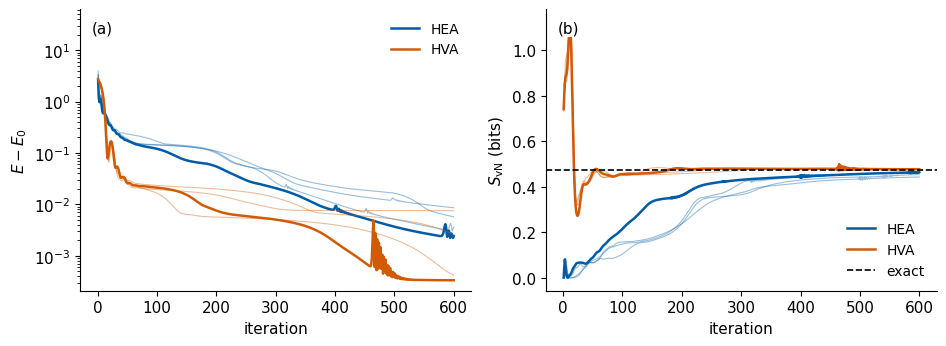

In [9]:
def training_figure(model, ansatze, name, half_gap=False):
    ex, it = EXACT[model], np.arange(1, STEPS + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.6))
    if half_gap:
        a1.axhline(ex["gap"] / 2, color="k", ls=":", lw=1.2, label=r"$\Delta E/2$")
    for a in ansatze:
        r = RUNS[(model, a)]
        for k in range(RESTARTS):
            best = k == r["best"]
            kw = dict(color=COL[a], lw=1.8 if best else 0.8, alpha=1.0 if best else 0.4, label=a if best else None)
            a1.semilogy(it, np.maximum(r["E"][:, k] - ex["E0"], 1e-12), **kw)
            a2.plot(it, r["S"][:, k], **kw)
    a2.axhline(ex["S"], color="k", ls="--", lw=1.2, label="exact")
    lo, hi = a1.get_ylim(); a1.set_ylim(lo, hi * 10)          # room for the panel label
    a1.set_xlabel("iteration"); a1.set_ylabel(r"$E-E_0$")
    a2.set_xlabel("iteration"); a2.set_ylabel(r"$S_{\rm vN}$ (bits)")
    a1.legend(fontsize=10, frameon=False, loc="upper right"); a2.legend(fontsize=10, frameon=False, loc="lower right")
    panel(a1, "a"); panel(a2, "b")
    fig.tight_layout(); save(fig, name); plt.show()

training_figure("TFIM h=1", ["HEA", "HVA"], "fig_lab070_training_tfim_critical")

Both ansätze lower the energy error by three to four orders of magnitude, and the best HVA restart, with 12 angles, ends below the best HEA restart, with 84 angles. The restarts of each ansatz end at different energies, so VQE keeps the best of several. The HEA starts from a product state and builds the entanglement slowly, so its entropy approaches the exact value from below. The HVA starts from the discretised sweep (12), overshoots the exact entropy during the first tens of iterations and then settles near it. The best HVA state has $\delta E\approx5\times10^{-5}$ and $\delta S\approx4\times10^{-3}$ bits, and the best HEA state has $\delta E\approx3\times10^{-4}$ and $\delta S\approx10^{-2}$ bits. Equations (8) and (9) explain the difference, since the energy error falls in proportion to the infidelity $1-F$ while the entropy error falls only as $\sqrt{1-F}$. The energy alone is therefore a weak test of the entanglement of the trained state. The short spikes late in some runs come from single large Adam steps taken when the running average of the squared gradient has become small. The energy then recovers within a few tens of iterations.

## 11. The Heisenberg chain

The same comparison for the Heisenberg chain uses the HEA and the SPA, both with six layers and 30 two-qubit gates.

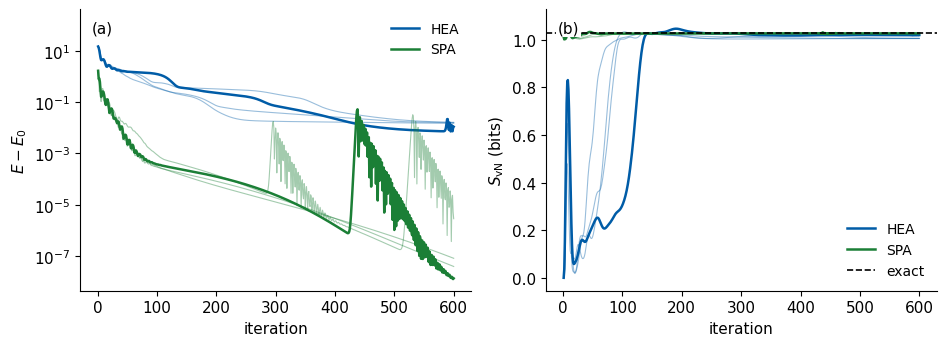

In [10]:
training_figure("XXZ Delta=1", ["HEA", "SPA"], "fig_lab070_training_xxz")

The SPA prepares the ground state to a relative energy error of about $10^{-9}$, and its entropy stays at the exact value from the first iterations. It starts from the singlet product, which already carries one bit across the middle cut and lies in the sector $\hat Z_{\rm tot}=0$, so the circuit only redistributes singlet correlations along the chain. The HEA has to build this structure from $|0\dots0\rangle$ and to remove the weight outside the sector. The entropy of its best restart jumps to about $0.8$ bits near iteration 10, drops back to between $0.1$ and $0.3$ bits while the energy decreases, and rises to the exact value near iteration 130. The other restarts make this rise between iterations 50 and 120. The final HEA state has $\delta E$ below $10^{-3}$ and $\delta S$ below $10^{-2}$ bits. The energy error of the SPA shows Adam spikes up to about $10^{-1}$ late in training, near iterations 300, 430 and 520, after which it falls back to its previous level.

## 12. The ordered Ising chain

At $h=0.5$ the exact ground state is close to the even superposition of the two ordered configurations,
$$|\psi_0\rangle\approx\frac{|0\dots0\rangle+|1\dots1\rangle}{\sqrt2} , \tag{17}$$
dressed by spin flips that the field creates, and the first excited state $|\psi_1\rangle$ is close to the odd superposition. The state (17) is a cat state, a superposition of two macroscopically different configurations, and across any cut it carries about one bit of entropy. The two levels form a doublet separated by the small gap $\Delta E$ from Section 2.

A trial state that lies within the doublet, $|\psi\rangle=a|\psi_0\rangle+b|\psi_1\rangle$ with $|a|^2+|b|^2=1$, has
$$\langle\hat\Pi\rangle=|a|^2-|b|^2,\qquad E-E_0=|b|^2\Delta E=\frac{1-\langle\hat\Pi\rangle}{2}\,\Delta E . \tag{18}$$
The symmetry-broken state $(|\psi_0\rangle+|\psi_1\rangle)/\sqrt2\approx|0\dots0\rangle$, dressed by spin flips, has $\langle\hat\Pi\rangle=0$, fidelity $F=1/2$ and an energy only $\Delta E/2$ above $E_0$. It is close to a product state and carries almost no entanglement. A circuit that reaches this state has a relative energy error of order $\Delta E/(2|E_0|)$, which is small on the scale of the coupling. Its fidelity and entropy are both far from the exact values, as the level scheme below summarises.

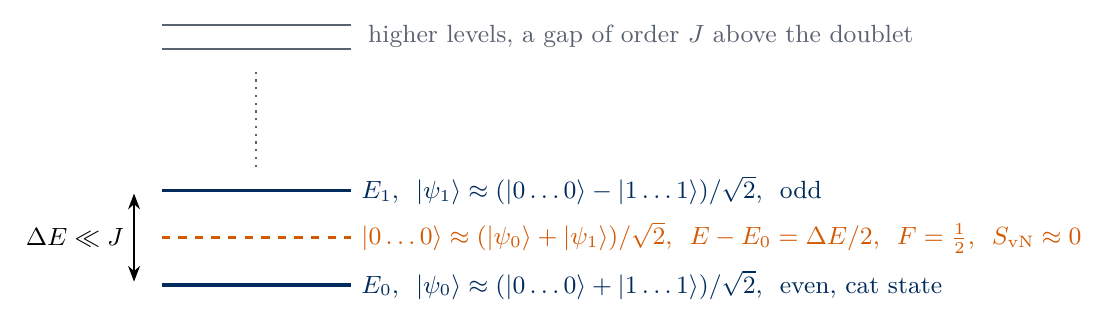

The even ground state and the odd first excited state form a doublet with a splitting $\Delta E$ much smaller than $J$, and the symmetry-broken state $|0\dots0\rangle$ lies halfway between them with $F=1/2$ and almost no entanglement.

HEA: weight in the doublet |c0|^2 + |c1|^2 = 0.9999,  <P> = +0.0186
HEA: E - E_0 = 0.01176,  (1 - <P>) gap / 2 = 0.01151,  gap / 2 = 0.01173
exact: p(000000) = 0.398, p(111111) = 0.398, others = 0.204
HEA  : p(000000) = 0.812, p(111111) = 0.000, others = 0.188
HVA  : p(000000) = 0.392, p(111111) = 0.392, others = 0.215


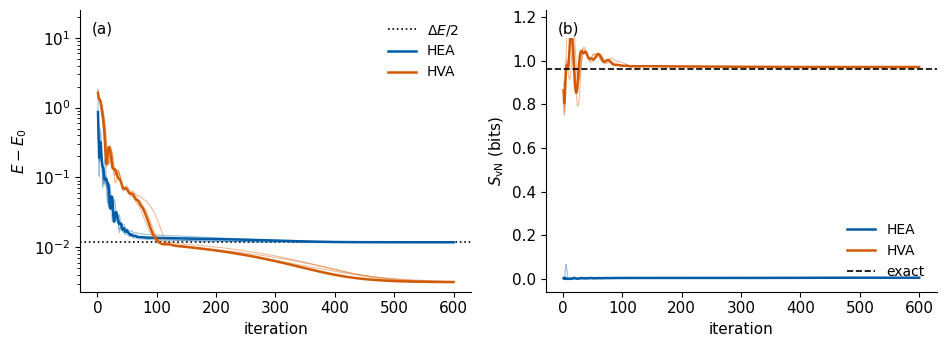

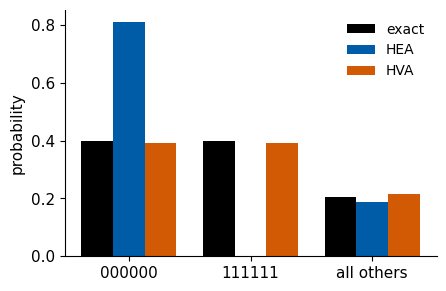

In [11]:
training_figure("TFIM h=0.5", ["HEA", "HVA"], "fig_lab070_training_tfim_ordered", half_gap=True)

# the HEA state in the doublet picture, equation (18)
ex = EXACT["TFIM h=0.5"]
r = RUNS[("TFIM h=0.5", "HEA")]
psi_hea = np.asarray(hea_state(jnp.asarray(r["theta"][r["best"]]), L_MAIN))
r_hva = RUNS[("TFIM h=0.5", "HVA")]
psi_hva = np.asarray(hva_state(jnp.asarray(r_hva["theta"][r_hva["best"]]), L_MAIN))
c0, c1 = abs(np.vdot(ex["psi0"], psi_hea)) ** 2, abs(np.vdot(ex["psi1"], psi_hea)) ** 2
P_hea = float(np.real(np.vdot(psi_hea, PARITY @ psi_hea)))
dE_hea = float(np.real(np.vdot(psi_hea, MODELS["TFIM h=0.5"] @ psi_hea))) - ex["E0"]
print(f"HEA: weight in the doublet |c0|^2 + |c1|^2 = {c0 + c1:.4f},  <P> = {P_hea:+.4f}")
print(f"HEA: E - E_0 = {dE_hea:.5f},  (1 - <P>) gap / 2 = {(1 - P_hea) * ex['gap'] / 2:.5f},  gap / 2 = {ex['gap'] / 2:.5f}")
assert c0 + c1 > 0.99
NUMBERS["OrdHeaParity"] = f"{P_hea:+.3f}"
NUMBERS["OrdHeaDoubletWeight"] = f"{c0 + c1:.3f}"
NUMBERS["OrdHeaEnergyError"] = f"{dE_hea:.4f}"
NUMBERS["OrdHalfGap"] = f"{ex['gap'] / 2:.4f}"

# what a measurement in the computational basis returns: probabilities of 000000, 111111 and all other strings
def string_probs(psi):
    p = np.abs(np.asarray(psi)) ** 2
    return [p[0], p[-1], 1 - p[0] - p[-1]]
probs = {"exact": string_probs(ex["psi0"]), "HEA": string_probs(psi_hea), "HVA": string_probs(psi_hva)}
fig, ax = plt.subplots(figsize=(4.8, 3.2))
xs = np.arange(3)
for j, (lab, col) in enumerate((("exact", "black"), ("HEA", COL["HEA"]), ("HVA", COL["HVA"]))):
    ax.bar(xs + (j - 1) * 0.26, probs[lab], width=0.26, color=col, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(["000000", "111111", "all others"])
ax.set_ylabel("probability"); ax.legend(fontsize=10, frameon=False)
save(fig, "fig_lab070_ordered_bitstrings"); plt.show()
for lab, p in probs.items():
    print(f"{lab:5s}: p(000000) = {p[0]:.3f}, p(111111) = {p[1]:.3f}, others = {p[2]:.3f}")
NUMBERS["OrdHeaPZeros"] = f"{probs['HEA'][0]:.2f}"
NUMBERS["OrdHeaPOnes"] = f"{probs['HEA'][1]:.3f}"
NUMBERS["OrdExactPZeros"] = f"{probs['exact'][0]:.2f}"

The two ansätze end at energies that differ by little on the scale of the coupling, yet they prepare different states. Every HEA restart descends into the symmetry-broken branch near $|0\dots0\rangle$, from which it starts, and stays there with fidelity close to $1/2$ and an entropy close to zero. Its state lies almost entirely within the doublet, its parity is close to zero, and its energy error sits on the dotted line $\Delta E/2$ of equation (18). Turning this branch into the cat state would lower the energy by only $\Delta E/2$. It would require a coherent superposition with the configuration $|1\dots1\rangle$, which differs from $|0\dots0\rangle$ in all six spins. The outcome depends on two properties together, the missing parity symmetry of the HEA and its start near $|0\dots0\rangle$, which lies in one branch. Exercise 7 tests a symmetric start. The HVA keeps the parity at $+1$ at every iteration and cannot enter the symmetry-broken branch. All its restarts reach the cat state, with fidelity close to one and the exact entropy of almost one bit.

A device measuring in the computational basis would see the difference directly in the bit strings. The exact ground state and the HVA state return $000000$ and $111111$ in nearly equal shares, whereas the HEA state returns $000000$ in most shots and $111111$ almost never. Measurements along $z$ alone cannot distinguish the cat state from an equal mixture of the two branches, and the parity $\langle\hat\Pi\rangle$, measured in the all-$x$ setting, decides between them.

## 13. Energy error and state error

Every iteration of the six runs gives one trial state with its energy, entropy and fidelity. The figure plots, for all recorded states, the energy error in units of the gap (a) and the entropy error (b) against the infidelity $1-F$. The solid line in (a) is the lower bound of equation (7), $(E-E_0)/\Delta E=1-F$. The dashed line in (b) is $\sqrt{1-F}$, the scaling of equation (9). The code asserts the bound (7) for every recorded state.

bound (7) holds for all 14400 recorded states; smallest ratio (E - E_0) / [gap (1 - F)] = 1.021


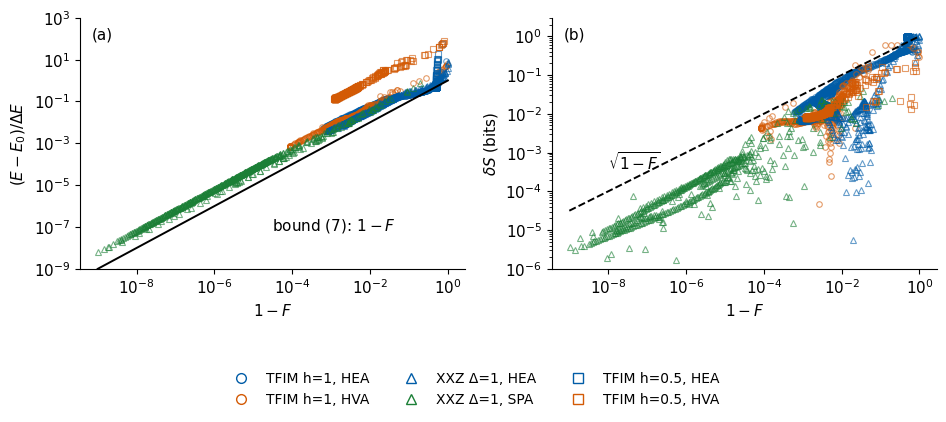

In [12]:
MARK = {"TFIM h=1": "o", "TFIM h=0.5": "s", "XXZ Delta=1": "^"}       # marker per model, colour per ansatz
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.8))
n_states, min_ratio = 0, np.inf
for (model, ansatz), r in RUNS.items():
    ex = EXACT[model]
    inf = 1 - r["F"].ravel(); dE = (r["E"].ravel() - ex["E0"]) / ex["gap"]; dS = np.abs(r["S"].ravel() - ex["S"])
    assert np.all(dE >= inf - 1e-9)                                    # equation (7) for every recorded state
    keep = inf > 1e-12
    min_ratio = min(min_ratio, np.min(dE[keep] / inf[keep])); n_states += inf.size
    sel = slice(None, None, 5)
    kw = dict(ls="none", marker=MARK[model], ms=4, mfc="none", mew=0.8, color=COL[ansatz], alpha=0.6)
    a1.loglog(inf[sel], dE[sel], **kw)
    a2.loglog(inf[sel], np.maximum(dS[sel], 1e-8), **kw)
xx = np.logspace(-9, 0, 50)
a1.loglog(xx, xx, "k-", lw=1.4); a2.loglog(xx, np.sqrt(xx), "k--", lw=1.4)
a1.text(3e-5, 3e-7, r"bound (7): $1-F$", fontsize=11, rotation=0, ha="left", va="top")
a2.text(1e-8, 3e-4, r"$\sqrt{1-F}$", fontsize=11, ha="left", va="bottom")
handles = [plt.Line2D([], [], ls="none", marker=MARK[m], mfc="none", color=COL[a], ms=7, label=f"{m.replace('Delta', 'Δ')}, {a}")
           for (m, a) in RUNS]
a1.set_xlabel(r"$1-F$"); a1.set_ylabel(r"$(E-E_0)/\Delta E$")
a2.set_xlabel(r"$1-F$"); a2.set_ylabel(r"$\delta S$ (bits)")
a1.set_ylim(1e-9, 1e3); a2.set_ylim(1e-6, 3)
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.12))
panel(a1, "a"); panel(a2, "b")
fig.tight_layout(rect=(0, 0.1, 1, 1)); save(fig, "fig_lab070_error_orders"); plt.show()
print(f"bound (7) holds for all {n_states} recorded states; smallest ratio (E - E_0) / [gap (1 - F)] = {min_ratio:.3f}")
NUMBERS["RecordedStates"] = str(n_states)
NUMBERS["BoundMinRatio"] = f"{min_ratio:.2f}"

All points of panel (a) lie above the bound, as equation (7) requires, and follow a slope of one on the logarithmic axes. The points of the ordered chain touch the bound at the symmetry-broken HEA states near $1-F=1/2$, where nearly all the error sits in the first excited state. In panel (b) the entropy errors follow the slope one half of $\sqrt{1-F}$, so the entropy error falls as the square root of the infidelity while the energy error falls linearly with it. At small infidelity the entropy is therefore the more sensitive test of the state. The downward spikes in (b) are iterations at which $S_{\rm vN}$ passes through the exact value.

## 14. Comparison of the ansätze

The table collects the best restart of every run. Its columns give the number of angles $n$, the number of parametrised Pauli rotations $n_{\rm rot}$, the number of two-qubit gates and the number $2n_{\rm rot}G$ of distinct circuits that one gradient (16) would need on a device, each run with $M$ shots. The HEA has one rotation per angle, the HVA applies each of its shared angles in $N-1$ or $N$ rotations, and each SPA gate (13) consists of three rotations, $\hat R_{xx}(\theta_{xy})\hat R_{yy}(\theta_{xy})\hat R_{zz}(\theta_{zz})$, so $\theta_{xy}$ occurs twice. The last four columns give the relative energy error $\delta E$, the fidelity $F$, the entropy error $\delta S$ and the number of restarts that reach $F>0.99$.

In [13]:
SETTINGS = {"TFIM h=1": 2, "TFIM h=0.5": 2, "XXZ Delta=1": 3}

def rotations(ansatz, L):
    # parametrised Pauli rotations (gate occurrences of angles), counted along the circuits of Sections 5 to 7
    if ansatz == "HEA":
        return sum(2 for block in range(L + 1) for q in range(N))                         # R_y and R_z per qubit and block
    if ansatz == "HVA":
        return sum((N - 1) + N for layer in range(L))                                     # R_zz on every bond, R_x on every qubit
    return sum(3 for layer in range(L) for bond in BONDS)                                 # G = R_xx(t_xy) R_yy(t_xy) R_zz(t_zz)
table = []
for (model, ansatz), r in RUNS.items():
    size = ANSATZ[ansatz]["size"](L_MAIN)
    table.append({"model": model, "ansatz": ansatz, "L": L_MAIN, "n": size["n"], "n_rot": rotations(ansatz, L_MAIN), "two-qubit gates": size["two_qubit"],
                  "circuits per gradient": 2 * rotations(ansatz, L_MAIN) * SETTINGS[model], "dE (rel.)": r["rel_err"], "F": r["fid"],
                  "dS (bits)": r["dS"], "restarts F>0.99": f"{int(np.sum(r['F_fin'] > 0.99))}/{RESTARTS}"})
TABLE = pd.DataFrame(table)
print(TABLE.to_string(index=False, formatters={"dE (rel.)": lambda x: f"{x:.1e}", "F": lambda x: f"{x:.5f}", "dS (bits)": lambda x: f"{x:.1e}"}))
TAG = {"TFIM h=1": "Crit", "TFIM h=0.5": "Ord", "XXZ Delta=1": "Heis"}
for (model, ansatz), r in RUNS.items():
    t = TAG[model] + ansatz.capitalize()
    NUMBERS[f"RelErr{t}"] = sci(r["rel_err"])
    NUMBERS[f"Fid{t}"] = f"{r['fid']:.4f}"
    NUMBERS[f"DS{t}"] = sci(r["dS"])
    NUMBERS[f"Svn{t}"] = f"{r['S_fin'][r['best']]:.3f}"
for a in ANSATZ:
    NUMBERS[f"Params{a.capitalize()}"] = str(ANSATZ[a]["size"](L_MAIN)["n"])
NUMBERS["TwoQubitGates"] = str((N - 1) * L_MAIN)
NUMBERS["Steps"] = str(STEPS); NUMBERS["Restarts"] = str(RESTARTS); NUMBERS["Layers"] = str(L_MAIN)
assert RUNS[("TFIM h=0.5", "HEA")]["fid"] < 0.6 and RUNS[("TFIM h=0.5", "HVA")]["fid"] > 0.99
t_core = time.perf_counter() - started
print(f"core route (Sections 1 to 14) finished after {t_core:.1f} s")
NUMBERS["RuntimeCore"] = f"{t_core:.0f}"

      model ansatz  L  n  n_rot  two-qubit gates  circuits per gradient dE (rel.)       F dS (bits) restarts F>0.99
   TFIM h=1    HEA  6 84     84               30                    336   3.4e-04 0.99936   1.1e-02             4/4
   TFIM h=1    HVA  6 12     66               30                    264   4.6e-05 0.99991   4.4e-03             4/4
XXZ Delta=1    HEA  6 84     84               30                    504   7.3e-04 0.99920   7.6e-03             4/4
XXZ Delta=1    SPA  6 60     90               30                    540   1.3e-09 1.00000   4.1e-06             4/4
 TFIM h=0.5    HEA  6 84     84               30                    336   2.1e-03 0.50929   9.6e-01             0/4
 TFIM h=0.5    HVA  6 12     66               30                    264   5.7e-04 0.99878   8.0e-03             4/4
core route (Sections 1 to 14) finished after 38.4 s


At equal depth and equal two-qubit gate count, the ansätze built for their Hamiltonian need fewer angles and reach better states. The SPA prepares the Heisenberg ground state to numerical precision with every restart. The HVA, with 12 angles, reaches the Ising ground state with every restart at both fields. The HEA, with 84 angles, ends at a lower fidelity on every model and at $F\approx1/2$ on the ordered chain, a result of its start near $|0\dots0\rangle$ together with its missing parity symmetry. The cost of a hardware gradient, $2n_{\rm rot}G$ circuits, counts the gate occurrences of the angles, so the HVA with 12 free angles still needs 264 circuits per gradient. The three ansätze need between 264 and 540. These advantages are tied to the model, since the HVA is defined by one Hamiltonian and the SPA reaches only states with $\hat Z_{\rm tot}=0$. The core route ends here.

## 15. Circuit depth

We repeat the training of the HEA and the HVA on both Ising chains for $L=1$ to $6$ layers, with the settings of Section 9. The circuits with a variable number of active layers from Section 8 let one compiled function train all depths and restarts at once. The figure shows the relative energy error (a) and the infidelity (b) of the best restart at each depth, with solid lines for the critical chain and dashed lines for the ordered chain.

depth scan time 42.2 s
L                 1        2        3        4        5        6
ansatz h                                                        
HEA    0.5  5.0e-01  4.9e-01  4.9e-01  4.9e-01  4.9e-01  4.9e-01
       1.0  3.6e-01  1.0e-01  2.5e-03  1.0e-03  4.2e-04  3.0e-04
HVA    0.5  4.8e-01  3.1e-01  1.7e-01  6.4e-02  4.1e-03  1.2e-03
       1.0  8.9e-02  3.2e-02  1.1e-02  2.7e-03  2.5e-03  2.2e-04


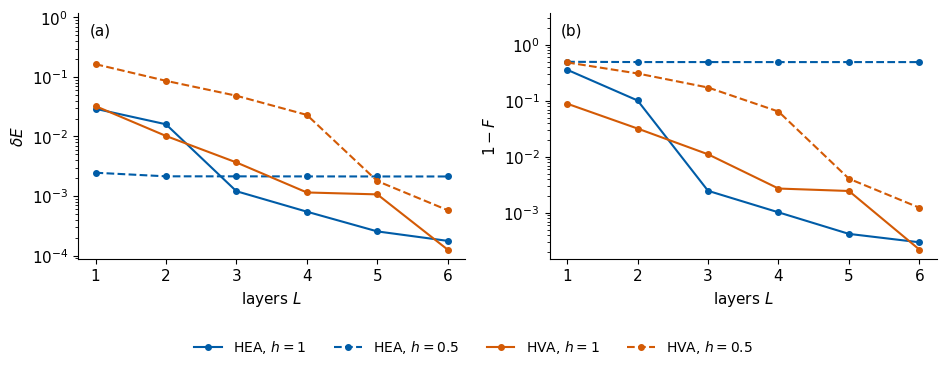

In [14]:
DEPTHS = np.arange(1, L_MAX + 1)
depth_batch = jnp.repeat(jnp.asarray(DEPTHS), RESTARTS)          # restarts of depth 1, then of depth 2, ...
DEPTH_STATE = {"HEA": hea_state_depth, "HVA": hva_state_depth}
DEPTH = {}
t_depth = time.perf_counter()
for ansatz in ("HEA", "HVA"):
    run = make_trainer(DEPTH_STATE[ansatz], ANSATZ[ansatz]["lr"], STEPS)    # one compiled function for all depths
    for model in ("TFIM h=1", "TFIM h=0.5"):
        key, sub = jax.random.split(key)
        ex = EXACT[model]
        if ansatz == "HEA":
            theta0 = 0.1 * jax.random.normal(sub, (depth_batch.size, 2 * N * (L_MAX + 1)))
        else:   # equation (12) for each depth L, padded with zeros for the inactive layers
            ramps = np.concatenate([np.pad(hva_ramp(L, FIELD[model]), (0, 2 * (L_MAX - L)))[None].repeat(RESTARTS, 0) for L in DEPTHS])
            theta0 = jnp.asarray(ramps) + 0.02 * jax.random.normal(sub, ramps.shape)
        _, _, (E, S, F), cost = run(theta0, depth_batch, ex["H"], jnp.asarray(ex["psi0"]), no_penalty, 0.0)
        E, S, F, cost = (np.asarray(a).reshape(len(DEPTHS), RESTARTS) for a in (E, S, F, cost))
        for i, L in enumerate(DEPTHS):
            b = int(np.argmin(cost[i]))
            DEPTH[(ansatz, model, int(L))] = dict(rel_err=float((E[i, b] - ex["E0"]) / abs(ex["E0"])), inf=float(1 - F[i, b]),
                                                  dS=float(abs(S[i, b] - ex["S"])))
print(f"depth scan time {time.perf_counter() - t_depth:.1f} s")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ansatz in ("HEA", "HVA"):
    for model, ls in (("TFIM h=1", "-"), ("TFIM h=0.5", "--")):
        a1.semilogy(DEPTHS, [DEPTH[(ansatz, model, L)]["rel_err"] for L in DEPTHS], ls, marker="o", ms=4, color=COL[ansatz],
                    label=f"{ansatz}, $h={FIELD[model]:g}$")
        a2.semilogy(DEPTHS, [max(DEPTH[(ansatz, model, L)]["inf"], 1e-12) for L in DEPTHS], ls, marker="o", ms=4, color=COL[ansatz])
for ax in (a1, a2):
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi * 5)
a1.set_xlabel("layers $L$"); a1.set_ylabel(r"$\delta E$")
a2.set_xlabel("layers $L$"); a2.set_ylabel(r"$1-F$")
fig.legend(*a1.get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.04))
panel(a1, "a"); panel(a2, "b")
fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, "fig_lab070_depth"); plt.show()
print(pd.DataFrame([{"ansatz": a, "h": FIELD[m], "L": L, "1-F": f"{v['inf']:.1e}"} for (a, m, L), v in DEPTH.items()])
      .pivot_table(index=["ansatz", "h"], columns="L", values="1-F", aggfunc="first").to_string())
for L in DEPTHS:
    NUMBERS[f"DepthInfHvaOrd{'ABCDEF'[L - 1]}"] = sci(DEPTH[("HVA", "TFIM h=0.5", int(L))]["inf"])
    NUMBERS[f"DepthInfHeaOrd{'ABCDEF'[L - 1]}"] = f"{DEPTH[('HEA', 'TFIM h=0.5', int(L))]['inf']:.2f}"

On the critical chain both errors fall steadily with depth for both ansätze. Between three and five layers the HEA, with $2N=12$ angles per layer against two for the HVA, is the more accurate of the two. On the ordered chain the HEA remains at every depth in the branch into which it descends, so its infidelity stays at $1-F\approx1/2$ and its energy error near $\Delta E/(2|E_0|)$. The HVA infidelity on the ordered chain drops by more than an order of magnitude between four and five layers. The cat state (17) correlates the two ends of the chain, $N-1=5$ bonds apart. Each layer of equation (11) extends the light cone of a spin by one bond in each direction, so the light cones of the two end spins overlap only from $L=3$ on, and only then can the ends become correlated. With two shared angles per layer the HVA reaches the cat state accurately only at five layers. The entanglement bound (15) allows one bit already at $L=1$, so the required depth comes from the range of the correlations.

## 16. The first excited state

Variational quantum deflation (VQD) finds excited states with the same circuits [9]. After a VQE run has produced an approximate ground state $|\tilde\psi_0\rangle$, a second run minimises
$$C(\boldsymbol\theta)=E(\boldsymbol\theta)+\lambda\,|\langle\tilde\psi_0|\psi(\boldsymbol\theta)\rangle|^2 , \tag{19}$$
where the penalty weight $\lambda$ raises the cost of any overlap with the ground state. If $|\tilde\psi_0\rangle$ were exact, the cost of a trial state $\sum_nc_n|n\rangle$ would be $\sum_n|c_n|^2E_n+\lambda|c_0|^2$, the energy of a Hamiltonian whose ground level is moved up to $E_0+\lambda$. For $\lambda>\Delta E$ its minimum is $E_1$, reached at the first excited state, as sketched below.

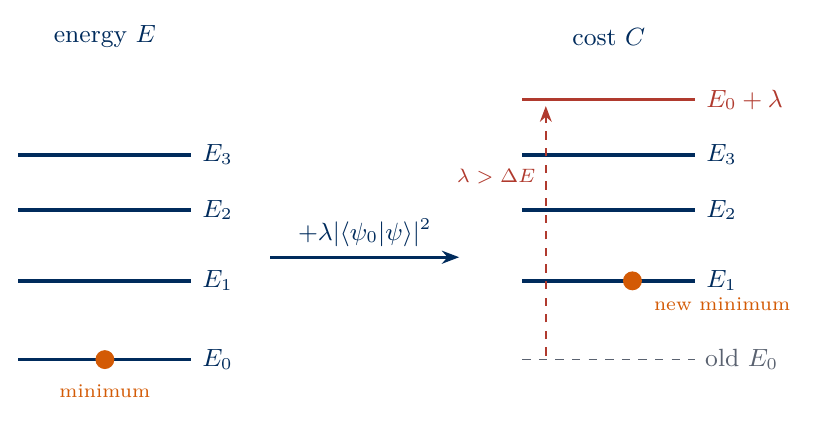

The penalty lifts the ground level to $E_0+\lambda$, so for $\lambda>\Delta E$ the lowest level of the cost, and its minimum, is $E_1$.

 On a device the overlap is estimated by applying the trial circuit followed by the inverse of the ground-state circuit and counting the outcome $0\dots0$, since $|\langle0\dots0|\hat U(\tilde{\boldsymbol\theta}_0)^\dagger\hat U(\boldsymbol\theta)|0\dots0\rangle|^2=|\langle\tilde\psi_0|\psi(\boldsymbol\theta)\rangle|^2$.

We apply VQD to the critical Ising chain with the HEA, the best trained HEA ground state as $|\tilde\psi_0\rangle$ and $\lambda=2J$, larger than the gap. The first excited state is odd under $\hat\Pi$, so the HVA, confined to even states, cannot reach it. The figure shows, against the iteration, the energy (a) and the infidelity $1-F_1$ with the exact first excited state (b), where $F_1=|\langle\psi_1|\psi\rangle|^2$. Dashed lines mark the exact $E_0$ and $E_1$.

VQE ground state: E_0 = -7.29378 (exact -7.29623)
VQD first excited state: E_1 = -6.81197 (exact -6.81408), F_1 = 0.9995, overlap with VQE state = 1.3e-05
gap from VQE + VQD = 0.4818 (exact 0.4821)
final F_1 of all restarts: [0.9988 0.9993 0.9995 0.9987]


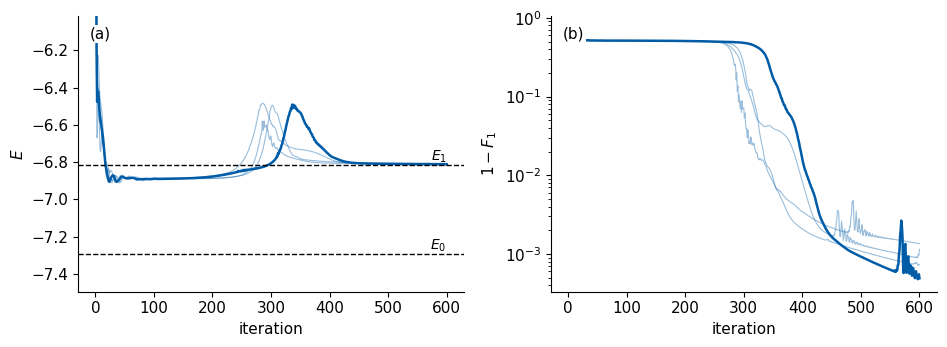

In [15]:
model, W = "TFIM h=1", 2.0
ex, r0 = EXACT[model], RUNS[(model, "HEA")]
psi0_vqe = hea_state(jnp.asarray(r0["theta"][r0["best"]]), L_MAIN)          # trained ground state from Section 10
E0_vqe = float(energy(psi0_vqe, ex["H"]))
key, sub = jax.random.split(key)
theta_x, hist_x, (E_x, S_x, F_x), cost_x = TRAINER["HEA"](initial_angles("HEA", model, L_MAIN, sub), DEPTH_MAIN, ex["H"],
                                                         jnp.asarray(ex["psi1"]), psi0_vqe, W)
E_x, F_x, S_x = np.asarray(E_x), np.asarray(F_x), np.asarray(S_x)
b = int(np.argmin(np.asarray(cost_x)))
overlap = float(jnp.abs(jnp.vdot(psi0_vqe, hea_state(theta_x[b], L_MAIN))) ** 2)
E1_vqd, gap_vqd = E_x[b], E_x[b] - E0_vqe
print(f"VQE ground state: E_0 = {E0_vqe:.5f} (exact {ex['E0']:.5f})")
print(f"VQD first excited state: E_1 = {E1_vqd:.5f} (exact {ex['E1']:.5f}), F_1 = {F_x[b]:.4f}, overlap with VQE state = {overlap:.1e}")
print(f"gap from VQE + VQD = {gap_vqd:.4f} (exact {ex['gap']:.4f})")
print(f"final F_1 of all restarts: {np.round(F_x, 4)}")

it = np.arange(1, STEPS + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.6))
for k in range(RESTARTS):
    kw = dict(color=COL["HEA"], lw=1.8 if k == b else 0.8, alpha=1.0 if k == b else 0.4)
    a1.plot(it, np.asarray(hist_x[0][:, k]), **kw)
    a2.semilogy(it, np.maximum(1 - np.asarray(hist_x[2][:, k]), 1e-12), **kw)
a1.axhline(ex["E0"], color="k", ls="--", lw=1.0); a1.axhline(ex["E1"], color="k", ls="--", lw=1.0)
a1.text(STEPS, ex["E0"], r"$E_0$", ha="right", va="bottom", fontsize=10); a1.text(STEPS, ex["E1"], r"$E_1$", ha="right", va="bottom", fontsize=10)
a1.set_ylim(ex["E0"] - 0.2, ex["E1"] + 0.8)
a1.set_xlabel("iteration"); a1.set_ylabel(r"$E$")
a2.set_xlabel("iteration"); a2.set_ylabel(r"$1-F_1$")
panel(a1, "a"); panel(a2, "b")
fig.tight_layout(); save(fig, "fig_lab070_vqd"); plt.show()
NUMBERS["VqdEOne"] = f"{E1_vqd:.4f}"; NUMBERS["ExactEOne"] = f"{ex['E1']:.4f}"
NUMBERS["VqdGap"] = f"{gap_vqd:.4f}"; NUMBERS["VqdFidOne"] = f"{F_x[b]:.4f}"; NUMBERS["VqdWeight"] = f"{W:g}"

The energy first drops below $E_1$ and stays on a plateau for about two hundred iterations, with a fidelity of about one half with $|\psi_1\rangle$. By equation (7) an energy below $E_1$ requires weight on the ground state, so during the plateau the trial state still overlaps with $|\tilde\psi_0\rangle$ and part of the penalty remains. Once this overlap is removed, the energy rises briefly above $E_1$ and then settles on it, and the infidelity falls below $10^{-3}$. The gap obtained as the difference of the VQD and VQE energies agrees with the exact gap within $10^{-3}$. Errors of $|\tilde\psi_0\rangle$ propagate into the excited state, because the penalty acts on the approximate ground state and leaves a small admixture of the exact one unpenalised.


## 17. Phase diagram of a longer Ising chain

The two fields of Sections 10 and 12 lie on either side of the Ising transition. To follow the ground state across it, we train the HEA and the HVA on the Ising chain (1) with $N=8$ qubits at 18 fields between $h=0.1$ and $h=2$, with a denser grid near the critical field $h=J$. Every trained state is compared with exact diagonalisation.

For this study the Hamiltonian is never stored as a matrix. It acts on the rank-8 state tensor term by term. The bond terms are diagonal in the computational basis and multiply the amplitude of $b_0\dots b_{N-1}$ by $\sum_i z_iz_{i+1}$ with $z_i=1-2b_i$. The operator $\hat X_i$ flips bit $i$, which reverses the tensor along leg $i$ (`jnp.flip`). One application of $\hat{\mathcal H}_{\rm TFIM}$ then costs of order $N2^N$ operations and the memory of a few state vectors, whereas a dense matrix would need $4^N$ entries. The energy $\langle\psi|\hat{\mathcal H}|\psi\rangle$ and its gradient use the same function.

The exact reference uses this function as well. The Lanczos routine `eigsh` of SciPy needs only the product of the Hamiltonian with a vector, which we supply as a `LinearOperator` whose product calls the compiled JAX function. At small $h$ the two lowest levels form the near-degenerate doublet of Section 12, and Lanczos could return a mixture of them. We therefore apply the projector $(\hat I+\hat\Pi)/2$ on the even sector before and after $\hat{\mathcal H}$. The odd states of the projected operator have eigenvalue zero, which lies above the negative lowest even energy. The lowest eigenvector of the projected operator is therefore the even ground state, which is the ground state of the chain for every $h>0$. The code checks the matrix-free product and the energy at $h=1$ against the sparse matrix of Section 2.


In [16]:

from scipy.sparse.linalg import LinearOperator
N8 = 8
SHAPE8 = (2,) * N8
BITS8 = np.array(list(itertools.product([0, 1], repeat=N8)))
SPIN8 = 1 - 2 * BITS8
ZZ8 = jnp.asarray(sum(SPIN8[:, i] * SPIN8[:, i + 1] for i in range(N8 - 1)).reshape(SHAPE8).astype(float))   # sum_i z_i z_{i+1}
MZ8 = jnp.asarray((SPIN8.sum(axis=1) / N8).reshape(SHAPE8).astype(float))                                  # (1/N) sum_i z_i
ALL_LEGS = tuple(range(N8))

def tfim_apply(psi, h, J=1.0):
    # H_TFIM |psi> on the rank-N tensor: diagonal bond terms, and X_i = reversal of leg i
    out = -J * ZZ8 * psi
    for i in range(N8):
        out = out - h * jnp.flip(psi, axis=i)
    return out
tfim_apply_jit = jax.jit(tfim_apply)

def parity_even(t):
    # projector (I + P)/2; P flips every bit, i.e. reverses all legs
    return (t + jnp.flip(t, axis=ALL_LEGS)) / 2

def ground_state_matrix_free(h):
    def matvec(v):
        t = parity_even(jnp.asarray(v, dtype=CDTYPE).reshape(SHAPE8))
        return np.asarray(parity_even(tfim_apply_jit(t, h))).reshape(-1)
    op = LinearOperator((2 ** N8, 2 ** N8), matvec=matvec, dtype=complex)
    w, v = eigsh(op, k=1, which="SA")
    return w[0], v[:, 0]

# checks at h = 1 against the sparse Kronecker-product matrix
H8_sparse = tfim_hamiltonian(1.0, N=N8)
v_r = np.random.default_rng(70).normal(size=2 ** N8) + 1j * np.random.default_rng(71).normal(size=2 ** N8)
assert np.allclose(np.asarray(tfim_apply_jit(jnp.asarray(v_r).reshape(SHAPE8), 1.0)).reshape(-1), H8_sparse @ v_r, atol=TOL)
E_mf, _ = ground_state_matrix_free(1.0)
E_sp = eigsh(H8_sparse, k=1, which="SA")[0][0]
assert abs(E_mf - E_sp) < 1e-9
print(f"h = 1, N = 8: matrix-free Lanczos E_0 = {E_mf:.10f}, sparse-matrix Lanczos E_0 = {E_sp:.10f}")

H_GRID = np.unique(np.round(np.concatenate([[0.1, 0.3], np.linspace(0.2, 2.0, 10), np.linspace(0.85, 1.15, 7)]), 3))
t_ed = time.perf_counter()
ED8 = [ground_state_matrix_free(h) for h in H_GRID]
print(f"{len(H_GRID)} fields: {H_GRID.tolist()}")
print(f"matrix-free exact diagonalisation of {len(H_GRID)} fields in {time.perf_counter() - t_ed:.1f} s")


h = 1, N = 8: matrix-free Lanczos E_0 = -9.8379514475, sparse-matrix Lanczos E_0 = -9.8379514475
18 fields: [0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2, 1.4, 1.6, 1.8, 2.0]
matrix-free exact diagonalisation of 18 fields in 1.0 s



Besides the energy per site $E/N$ and the half-chain entropy (5), we record two magnetisations. The transverse magnetisation
$$m_x=\frac1N\sum_{i=0}^{N-1}\langle\hat X_i\rangle \tag{20}$$
measures the alignment with the field and tends to one for $h\gg J$. The ordering along $z$ needs more care. Since $\hat\Pi\hat Z_i\hat\Pi=-\hat Z_i$, every state of definite parity has $\langle\hat Z_i\rangle=0$, so the magnetisation $\langle\hat Z_i\rangle$ vanishes in the exact ground state of a finite chain on both sides of the transition. We use the parity-invariant order parameter
$$m_z=\sqrt{\Big\langle\Big(\frac1N\sum_{i=0}^{N-1}\hat Z_i\Big)^2\Big\rangle} , \tag{21}$$
which tends to one in the ordered phase and falls to a value of order $1/\sqrt N$ in the paramagnet. It takes the same value in the cat state (17) and in either of its symmetry-broken branches, so it cannot detect the trap of Section 12, which the entropy and the fidelity reveal.

Both ansätze have $L=8$ layers and therefore $(N-1)L=56$ two-qubit gates, with $n=144$ angles for the HEA and $n=16$ for the HVA. Every field is trained independently, from the starts of Section 9 (the HEA near $|0\dots0\rangle$, the HVA on the sweep (12) for that field), with two restarts and 800 Adam iterations. The learning rates are $0.05$ for the HEA and $0.02$ for the HVA, as in Section 9. One compiled function applies `jax.vmap` over the fields and the restarts and `jax.lax.scan` over the iterations and the layers. Independent starts keep the field values from influencing each other. Warm starts, which pass the trained angles of one field to its neighbour, would cost fewer iterations per field and are left as an exercise. This section takes about a minute.


In [17]:

L8, STEPS8, R8 = 8, 800, 2
LR8 = {"HEA": 0.05, "HVA": 0.02}
CZ8 = jnp.asarray(np.prod([(-1.0) ** (BITS8[:, q] * BITS8[:, q + 1]) for q in range(N8 - 1)], axis=0).reshape(SHAPE8))
ZERO8 = jnp.zeros(SHAPE8, dtype=CDTYPE).at[(0,) * N8].set(1.0)
PLUS8 = jnp.ones(SHAPE8, dtype=CDTYPE) / 2 ** (N8 / 2)

def hea8_state(theta):
    # equation (10) for N8 qubits and L8 layers, as a rank-N8 tensor
    th = theta.reshape(L8 + 1, N8, 2)
    def rotations(psi, t):
        for q in range(N8):
            psi = apply_1q(psi, rz(t[q, 1]) @ ry(t[q, 0]), q)
        return psi
    psi, _ = jax.lax.scan(lambda p, t: (rotations(p, t) * CZ8, None), ZERO8, th[:-1])
    return rotations(psi, th[-1])

def hva8_state(theta):
    # equation (11) for N8 qubits and L8 layers
    th = theta.reshape(L8, 2)
    def layer(psi, t):
        psi = psi * jnp.exp(-1j * t[0] * ZZ8)
        U = rx(2 * t[1])
        for q in range(N8):
            psi = apply_1q(psi, U, q)
        return psi, None
    return jax.lax.scan(layer, PLUS8, th)[0]

def observables8(psi, h, psi0):
    # E, m_x (20), m_z (21), half-chain S_vN (5), fidelity with the exact ground state, all matrix-free
    E = jnp.real(jnp.vdot(psi, tfim_apply(psi, h)))
    mx = sum(jnp.real(jnp.vdot(psi, jnp.flip(psi, axis=i))) for i in range(N8)) / N8
    mz = jnp.sqrt(jnp.sum(jnp.abs(psi) ** 2 * MZ8 ** 2))
    s = jnp.linalg.svd(psi.reshape(2 ** (N8 // 2), -1), compute_uv=False)
    p = s ** 2
    S = -jnp.sum(jnp.where(p > 1e-14, p * jnp.log2(jnp.where(p > 1e-14, p, 1.0)), 0.0))
    return E, mx, mz, S, jnp.abs(jnp.vdot(psi0, psi)) ** 2

def make_phase_trainer(state_fn, lr, steps):
    # Adam on E(theta, h), vmapped over restarts (inner) and fields (outer)
    def energy8(theta, h):
        psi = state_fn(theta)
        return jnp.real(jnp.vdot(psi, tfim_apply(psi, h)))
    grad8 = jax.vmap(jax.vmap(jax.grad(energy8), in_axes=(0, None)), in_axes=(0, 0))
    final8 = jax.vmap(jax.vmap(lambda t, h, p0: observables8(state_fn(t), h, p0), in_axes=(0, None, None)), in_axes=(0, 0, 0))
    b1, b2, eps = 0.9, 0.999, 1e-8
    @jax.jit
    def run(theta0, hs, psi0s):
        def step(carry, t):
            theta, m, v = carry
            g = grad8(theta, hs)
            m = b1 * m + (1 - b1) * g
            v = b2 * v + (1 - b2) * g ** 2
            theta = theta - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
            return (theta, m, v), None
        zeros = jnp.zeros_like(theta0)
        (theta, _, _), _ = jax.lax.scan(step, (theta0, zeros, zeros), jnp.arange(1, steps + 1))
        return final8(theta, hs, psi0s)
    return run

hs8 = jnp.asarray(H_GRID)
psi0s8 = jnp.asarray(np.stack([v for _, v in ED8]).reshape((len(H_GRID),) + SHAPE8))
exact8 = np.array([np.asarray(observables8(psi0s8[i], H_GRID[i], psi0s8[i])) for i in range(len(H_GRID))])   # E, m_x, m_z, S, F=1
assert np.allclose(exact8[:, 0], [w for w, _ in ED8], atol=1e-9) and np.allclose(exact8[:, 4], 1.0)
key, k_hea, k_hva = jax.random.split(key, 3)
theta0_8 = {"HEA": 0.1 * jax.random.normal(k_hea, (len(H_GRID), R8, 2 * N8 * (L8 + 1))),
            "HVA": jnp.asarray(np.stack([hva_ramp(L8, h) for h in H_GRID]))[:, None, :]
                   + 0.02 * jax.random.normal(k_hva, (len(H_GRID), R8, 2 * L8))}
PHASE = {}
t_phase = time.perf_counter()
for ansatz, fn in (("HEA", hea8_state), ("HVA", hva8_state)):
    t_a = time.perf_counter()
    E, mx, mz, S, F = (np.asarray(a) for a in make_phase_trainer(fn, LR8[ansatz], STEPS8)(theta0_8[ansatz], hs8, psi0s8))
    best8 = np.argmin(E, axis=1); ix = np.arange(len(H_GRID))          # lowest-energy restart at each field
    PHASE[ansatz] = dict(E=E[ix, best8], mx=mx[ix, best8], mz=mz[ix, best8], S=S[ix, best8], F=F[ix, best8])
    print(f"{ansatz}: {len(H_GRID)} fields x {R8} restarts x {STEPS8} iterations in {time.perf_counter() - t_a:.1f} s")
t_phase = time.perf_counter() - t_phase
print(f"phase-diagram training {t_phase:.1f} s")


HEA: 18 fields x 2 restarts x 800 iterations in 57.6 s
HVA: 18 fields x 2 restarts x 800 iterations in 35.9 s
phase-diagram training 93.5 s



The figure shows, against the field, the energy per site (a), its relative error $\delta E$ (b), the transverse magnetisation (20) (c), the order parameter (21) (d), the half-chain entropy (e) and the infidelity $1-F$ (f). Black lines are exact diagonalisation and the markers the best restart of each ansatz at each field.


    h   E0/N  S exact  m_z exact  dE HEA  F HEA  S HEA  dE HVA  F HVA  S HVA
0.100 -0.878    1.000      0.998 2.6e-07  0.500  0.000 2.6e-02  0.924  1.084
0.200 -0.888    1.000      0.992 1.3e-06  0.500  0.000 2.7e-02  0.920  1.111
0.300 -0.903    1.000      0.982 1.1e-05  0.500  0.001 1.5e-02  0.956  1.076
0.400 -0.926    1.000      0.966 8.7e-05  0.500  0.002 1.3e-02  0.961  1.080
0.600 -0.992    0.966      0.907 1.4e-03  0.507  0.009 8.1e-04  0.997  0.972
0.800 -1.094    0.777      0.790 6.7e-03  0.583  0.064 2.0e-04  0.999  0.787
0.850 -1.125    0.707      0.755 6.5e-03  0.755  0.234 1.5e-04  1.000  0.717
0.900 -1.158    0.638      0.722 9.5e-04  0.997  0.610 3.9e-04  0.999  0.644
0.950 -1.193    0.574      0.692 5.2e-04  0.998  0.555 4.0e-04  0.999  0.583
1.000 -1.230    0.515      0.664 5.7e-04  0.998  0.494 7.1e-04  0.997  0.528
1.050 -1.268    0.464      0.639 3.5e-04  0.999  0.451 5.1e-04  0.998  0.475
1.100 -1.307    0.419      0.616 4.1e-04  0.999  0.400 3.9e-04  0.999  0.428

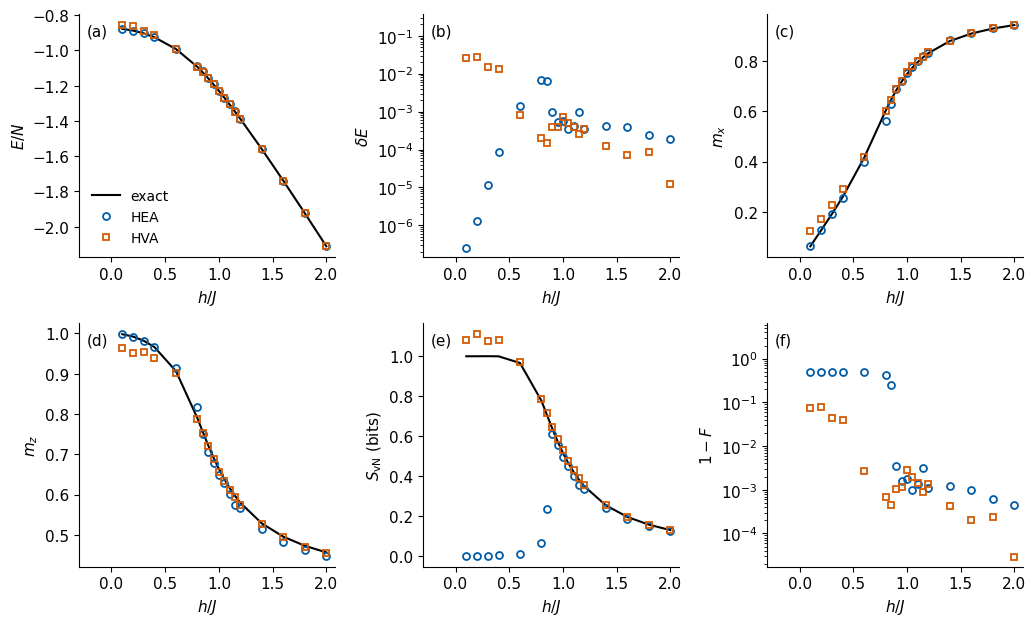

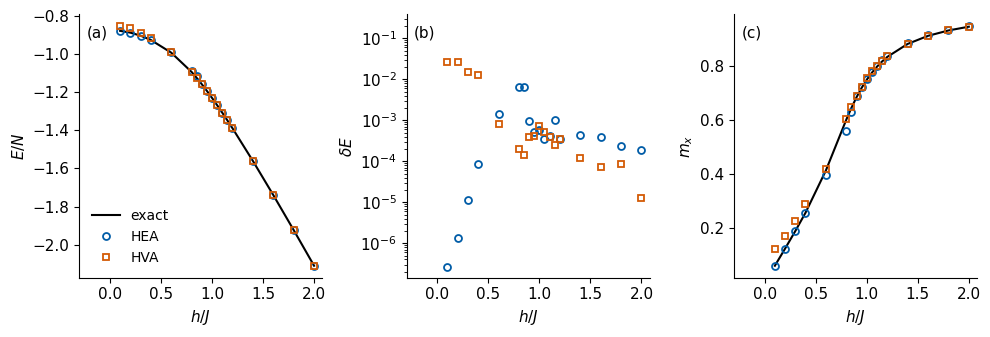

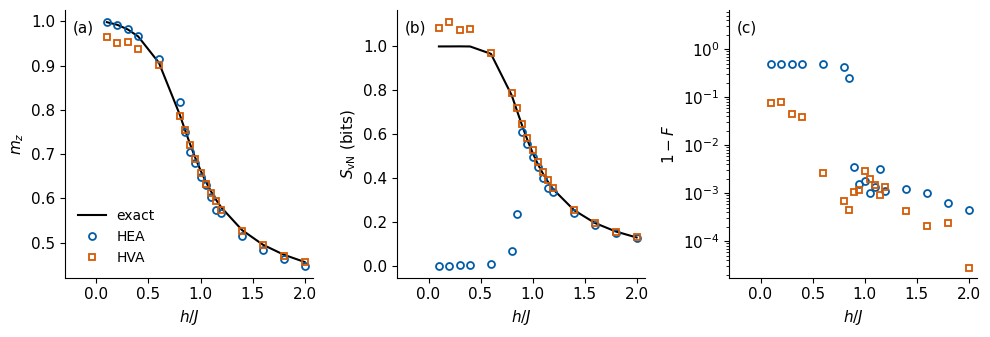

In [18]:

ex8 = dict(E=exact8[:, 0], mx=exact8[:, 1], mz=exact8[:, 2], S=exact8[:, 3])
PANELS = {"E": r"$E/N$", "dE": r"$\delta E$", "mx": r"$m_x$", "mz": r"$m_z$", "S": r"$S_{\rm vN}$ (bits)", "F": r"$1-F$"}

def phase_panel(ax, q, letter):
    # one observable of the phase diagram: exact line and the best restart of each ansatz
    if q in ("E", "mx", "mz", "S"):
        ax.plot(H_GRID, ex8[q] / (N8 if q == "E" else 1), "k-", lw=1.5, label="exact")
    for ansatz, mk in (("HEA", "o"), ("HVA", "s")):
        r8 = PHASE[ansatz]; kw = dict(ls="none", marker=mk, ms=5, mfc="none", mew=1.3, color=COL[ansatz], label=ansatz)
        if q == "E":
            ax.plot(H_GRID, r8["E"] / N8, **kw)
        elif q == "dE":
            ax.semilogy(H_GRID, (r8["E"] - ex8["E"]) / np.abs(ex8["E"]), **kw)
        elif q == "F":
            ax.semilogy(H_GRID, np.maximum(1 - r8["F"], 1e-8), **kw)
        else:
            ax.plot(H_GRID, r8[q], **kw)
    if q in ("dE", "F"):
        lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi * 8)
    ax.set_xlim(-0.3, 2.08); ax.set_xlabel(r"$h/J$"); ax.set_ylabel(PANELS[q]); panel(ax, letter)

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.4))
for ax, q, letter in zip(axes.ravel(), PANELS, "abcdef"):
    phase_panel(ax, q, letter)
axes[0, 0].legend(frameon=False, loc="lower left")
fig.tight_layout(); save(fig, "fig_lab070_phase_diagram"); plt.show()
for name, qs in (("fig_lab070_phase_diagram_a", ("E", "dE", "mx")), ("fig_lab070_phase_diagram_b", ("mz", "S", "F"))):
    fig, axes = plt.subplots(1, 3, figsize=(10.0, 3.5))
    for ax, q, letter in zip(axes, qs, "abc"):
        phase_panel(ax, q, letter)
    axes[0].legend(frameon=False, loc="lower left")
    fig.tight_layout(); save(fig, name); plt.show()

rows8 = []
for i, h in enumerate(H_GRID):
    row = {"h": h, "E0/N": ex8["E"][i] / N8, "S exact": ex8["S"][i], "m_z exact": ex8["mz"][i]}
    for a in ("HEA", "HVA"):
        row[f"dE {a}"] = f"{(PHASE[a]['E'][i] - ex8['E'][i]) / abs(ex8['E'][i]):.1e}"
        row[f"F {a}"] = PHASE[a]["F"][i]; row[f"S {a}"] = PHASE[a]["S"][i]
    rows8.append(row)
print(pd.DataFrame(rows8).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

def at(h):
    return int(np.argmin(np.abs(H_GRID - h)))
for a in ("HEA", "HVA"):
    A = a.capitalize()
    for tag, h in (("Deep", 0.2), ("Ordered", 0.6), ("Critical", 1.0), ("Para", 1.6)):
        NUMBERS[f"PhaseFid{A}{tag}"] = f"{PHASE[a]['F'][at(h)]:.3f}"
        NUMBERS[f"PhaseSvn{A}{tag}"] = f"{PHASE[a]['S'][at(h)]:.3f}"
        NUMBERS[f"PhaseRelErr{A}{tag}"] = sci((PHASE[a]["E"][at(h)] - ex8["E"][at(h)]) / abs(ex8["E"][at(h)]))
for tag, h in (("Deep", 0.2), ("Ordered", 0.6), ("Critical", 1.0), ("Para", 1.6)):
    NUMBERS[f"PhaseH{tag}"] = f"{h:g}"
    NUMBERS[f"PhaseSvnExact{tag}"] = f"{ex8['S'][at(h)]:.3f}"
    NUMBERS[f"PhaseMzExact{tag}"] = f"{ex8['mz'][at(h)]:.3f}"
NUMBERS["PhaseN"] = str(N8); NUMBERS["PhaseLayers"] = str(L8); NUMBERS["PhaseFields"] = str(len(H_GRID))
NUMBERS["PhaseTwoQubitGates"] = str((N8 - 1) * L8); NUMBERS["PhaseParamsHea"] = str(2 * N8 * (L8 + 1)); NUMBERS["PhaseParamsHva"] = str(2 * L8)
NUMBERS["PhaseSteps"] = str(STEPS8); NUMBERS["PhaseRestarts"] = str(R8); NUMBERS["PhaseRuntime"] = f"{t_phase:.0f}"
PHASE_SUMMARY = dict(N=N8, layers=L8, steps=STEPS8, restarts=R8, learning_rate=LR8, starts="independent per field",
                     fields=H_GRID.tolist(), exact={k: v.tolist() for k, v in ex8.items()},
                     ansatz={a: {k: v.tolist() for k, v in r.items()} for a, r in PHASE.items()},
                     n={"HEA": 2 * N8 * (L8 + 1), "HVA": 2 * L8}, two_qubit_gates=(N8 - 1) * L8, training_seconds=t_phase)


The energy per site (a) and the transverse magnetisation (c) of both ansätze follow the exact curves on the scale of the figure, and the relative energy error (b) stays below a few percent at every field. The other panels separate the two ansätze. Deep in the ordered phase the HEA has the smallest energy errors of the whole scan, below $10^{-5}$ for $h\le0.3$, while its fidelity is $1/2$ and its entropy zero. It sits in a symmetry-broken branch, as in Section 12, and its energy error shrinks with $h$ together with the splitting of the doublet, in line with equation (18). Its order parameter (d) agrees with the exact one, since $m_z$ takes the same value in a branch and in the cat state. The HEA stays trapped up to $h=0.85$, and from $h=0.9$ upward it reaches $F>0.99$ and comes close to the exact entropy.

The HVA keeps even parity at every field and never enters a symmetry-broken branch. It reaches $F>0.99$ at every field from $h=0.6$ upward and follows the exact entropy through the transition. For $h\le0.4$ its fidelity lies between $0.92$ and $0.96$, its entropy overshoots the exact one bit, and its energy error exceeds that of the trapped HEA. In this range the ranking of the two ansätze by energy is therefore the reverse of their ranking by fidelity. The HVA deficit is unrelated to the depth, since with eight layers the light cones of the two end spins, seven bonds apart, overlap after four layers. It comes from the optimisation with the budget used here, two restarts of 800 iterations. Exercise 9 explores a larger budget. Near $h=0.5$ the eight-qubit results agree with the six-qubit ones of Section 12 for both ansätze, and deeper in the ordered phase the eight-spin HVA reaches lower fidelities.

## 18. Exercises

1. Repeat the comparison of Section 11 for the XXZ chain at $\Delta=0.5$ and check whether the SPA still prepares the ground state with every restart.
2. Run VQD with the HVA on the critical Ising chain. Identify the state it converges to by its parity and its energy, and explain the result with equation (19).
3. Replace the start (12) of the HVA by uniformly random angles in $[-\pi,\pi)$ and compare the spread of the restarts on both Ising chains.
4. Write the CZ gate and the gate $\hat G$ of equation (13) as sums of products of operators on the two qubits, and find the number of terms $r$ for each.
5. Count the circuit executions that the HEA training of Section 10 would need on a device with 1000 shots per setting, using equation (16) and $G=2$.
6. Derive equation (18). Then compute $E-E_0$, $F$ and $\langle\hat\Pi\rangle$ for the state $(|\psi_0\rangle+e^{i\varphi}|\psi_1\rangle)/\sqrt2$ with a phase $\varphi$.
7. Start the HEA on the ordered chain from $|+\rangle^{\otimes N}$ by adding a layer of Hadamard gates, and check whether it still breaks the symmetry.
8. Repeat the phase diagram of Section 17 with warm starts, sweeping the field from $h=2$ down to $h=0.1$ and starting each field from the trained angles of the previous one, and compare the HEA fidelity in the ordered phase with the independent starts.
9. Train the HVA of Section 17 at $h=0.1$ and $h=0.4$ with more iterations, more restarts and other learning rates, and find which change raises its fidelity in the ordered phase.

## 19. Summary

The variational quantum eigensolver prepares a trial state with a parametrised circuit and lowers its energy by adjusting the gate angles. The variational principle bounds the energy from below, and the energy error bounds the infidelity through the gap. The energy error is of second order in the error of the state, whereas the half-chain entanglement entropy changes at first order. The entropy therefore exposes errors that a small energy error hides. At equal depth and two-qubit gate count, ansätze built from the Hamiltonian or restricted to its symmetry sector reach better states with far fewer angles than the hardware-efficient ansatz. In the ordered Ising chain the hardware-efficient ansatz, started near one ordered configuration and without parity symmetry, settles in a symmetry-broken branch with almost the correct energy, half the fidelity and no entanglement. The parity-conserving Hamiltonian-variational ansatz prepares the cat-like ground state once it has enough layers to correlate the two ends of the chain. Across the phase diagram of an eight-qubit Ising chain, the symmetry-broken states of the hardware-efficient ansatz have the smallest energy errors deep in the ordered phase and only half the fidelity. The Hamiltonian-variational ansatz follows the exact entanglement through the transition. Variational quantum deflation adds an overlap penalty to the same energy minimisation and gives the first excited state and the gap. All results use exact amplitudes and exact gradients, whereas on a device every energy, overlap and gradient is estimated from measured bit strings.

### References

1. A. Peruzzo, J. McClean, P. Shadbolt, M.-H. Yung, X.-Q. Zhou, P. J. Love, A. Aspuru-Guzik, and J. L. O'Brien, A variational eigenvalue solver on a photonic quantum processor, Nat. Commun. **5**, 4213 (2014), [doi:10.1038/ncomms5213](https://doi.org/10.1038/ncomms5213).
2. J. R. McClean, J. Romero, R. Babbush, and A. Aspuru-Guzik, The theory of variational hybrid quantum-classical algorithms, New J. Phys. **18**, 023023 (2016), [doi:10.1088/1367-2630/18/2/023023](https://doi.org/10.1088/1367-2630/18/2/023023).
3. A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow, and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), [doi:10.1038/nature23879](https://doi.org/10.1038/nature23879).
4. D. Wecker, M. B. Hastings, and M. Troyer, Progress towards practical quantum variational algorithms, Phys. Rev. A **92**, 042303 (2015), [doi:10.1103/PhysRevA.92.042303](https://doi.org/10.1103/PhysRevA.92.042303).
5. R. Wiersema, C. Zhou, Y. de Sereville, J. F. Carrasquilla, Y. B. Kim, and H. Yuen, Exploring entanglement and optimization within the Hamiltonian variational ansatz, PRX Quantum **1**, 020319 (2020), [doi:10.1103/PRXQuantum.1.020319](https://doi.org/10.1103/PRXQuantum.1.020319).
6. K. Mitarai, M. Negoro, M. Kitagawa, and K. Fujii, Quantum circuit learning, Phys. Rev. A **98**, 032309 (2018), [doi:10.1103/PhysRevA.98.032309](https://doi.org/10.1103/PhysRevA.98.032309).
7. M. Schuld, V. Bergholm, C. Gogolin, J. Izaac, and N. Killoran, Evaluating analytic gradients on quantum hardware, Phys. Rev. A **99**, 032331 (2019), [doi:10.1103/PhysRevA.99.032331](https://doi.org/10.1103/PhysRevA.99.032331).
8. D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).
9. O. Higgott, D. Wang, and S. Brierley, Variational quantum computation of excited states, Quantum **3**, 156 (2019), [doi:10.22331/q--156](https://doi.org/10.22331/q--156).
10. H. F. Trotter, On the product of semi-groups of operators, Proc. Am. Math. Soc. **10**, 545 (1959), [doi:10.1090/S0002-9939-1959-0108732-6](https://doi.org/10.1090/S0002-9939-1959-0108732-6).
11. M. Born and V. Fock, Beweis des Adiabatensatzes, Z. Phys. **51**, 165 (1928), [doi:10.1007/BF01343193](https://doi.org/10.1007/BF01343193).
12. J. Romero, R. Babbush, J. R. McClean, C. Hempel, P. J. Love, and A. Aspuru-Guzik, Strategies for quantum computing molecular energies using the unitary coupled cluster ansatz, Quantum Sci. Technol. **4**, 014008 (2019), [doi:10.1088/2058-9565/aad3e4](https://doi.org/10.1088/2058-9565/aad3e4).